# Target Marketing for Canadian Bank

Inclass Classification problem for AML-1413 Winter 2023

This leaderboard is calculated with approximately 40% of the test data. The final results will be based on the other 60%, so the final standings may be different.

**Business Case**: Target Marketing for Canadian Bank

**Data & Industry**

In this competition, you will be working on real customer data from a major international bank and the provided data are real, but de-identified to protect both customer and bank privacy.  So, you will have part of (not all) the challenges of dealing with real data which is an invaluable experience and knowledge that will significantly improves your success chance in the area of data science.

**Scenario**
In order to increase deposit balances, Bank “A” is looking to execute a marketing campaign. The campaign will target existing clients and will offer them promotional interest rates to attract deposit balances.

**The Task**
You are tasked to find right set of customers who are most likely to respond to the campaign.

**Datasets**
**Training data** –Training dataset contains 64000 observations from previous campaigns. Actual responses (labels) are in the variable called ‘Target’.

**Testing data** – contains 1478 observations with 36 variables and no labels.

**Dataset Description**

**File descriptions**
train.csv - the training set
test.csv - the test set

**Data fields**
**customer_id** - an anonymous id unique to a given customer
**Balance** : - Credit Card Balance
**PreviousCampaignResult** - Last Campaign Results
**Product1...Product6** - List of different products owned by the customer
**Transaction1...Transaction9** - Last 9 transactions made by the customer
**External Accounts 1...External Accounts 7** - External accounts held by the customer, including bills
**Activity Indicator** - Number of activities done the customer, including telebanking, going to the bank
**Regular Interaction Indicator** - How frequent the customer is interacting with the bank (Rating Scale)
**CompetitiveRate1 ... CompetitiveRate7** - Interest rates offered to the customer
**RateBefore** - Interest rates on the products, customer have before the competitive rates being offered
**ReferenceRate** -Interest rates on the products, the customer have after the negotiations made to the competitive rates being offered

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    confusion_matrix,
)
from typing import List, Tuple
from numpy import concatenate
from sklearn.semi_supervised import LabelPropagation
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from scipy import stats
from sklearn.cluster import DBSCAN
from tqdm.notebook import tqdm, tqdm_notebook
from sklearn.metrics import r2_score

np.seterr(divide="ignore", invalid="ignore")
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

In [4]:
class OutliersData:
    def __init__(self, data: pd.DataFrame):
        """
        Initialize Outliers Class
        :param data: Initial Dataframe
        """
        self.data = data.copy()
        self.data = self.data[~self.data.isna()]

    def z_score_outlier(self) -> List:
        """
        The Z score method is a statistical technique used to determine how many standard deviations
        a data point is away from the mean. This method is useful in analyzing data and determining
        the probability of an event occurring. The Z score is calculated by subtracting the mean
        from the data point and then dividing the result by the standard deviation. The resulting
        number indicates the number of standard deviations the data point is away from the mean.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        m = np.mean(self.data)
        sd = np.std(self.data)
        for i in self.data:
            z = (i - m) / sd
            if np.abs(z) > 3:
                out.append(i)
        return out

    def zr_score_outlier(self) -> List:
        """
        The Robust Z-score method is an extension of the Z-score and MAD methods for outlier detection.
        It is also known as the "Median Absolute Deviation Z-score" method. Like the MAD method,
        it uses the median and absolute deviation from the median to determine how many median absolute
        deviations an observation is from the median. However, it also incorporates a correction
        factor based on the sample size and the kurtosis of the data, which improves its performance
        when the data is not normally distributed. This makes the Robust Z-score method a more robust
        technique for outlier detection than the standard Z-score method.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        med = np.median(self.data)
        ma = stats.median_abs_deviation(self.data)
        for i in self.data:
            z = (0.6745 * (i - med)) / (np.median(ma))
            if np.abs(z) > 3:
                out.append(i)
        return out

    def iqr_outliers(self) -> List:
        """
        The Interquartile Range (IQR) is a measure of the spread of a dataset that is less affected by
        outliers than the standard deviation. It is calculated as the difference between the third
        quartile and the first quartile. To detect outliers using the IQR method, any value that falls
        outside the range of -1.5 times IQR to 1.5 times IQR is considered an outlier. This range is
        also called the "inner fences" or "whiskers" of the box plot. The IQR method is a simple and
        robust way to identify outliers in a dataset.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        q1 = self.data.quantile(0.25)
        q3 = self.data.quantile(0.75)
        iqr = q3 - q1
        lower_tail = q1 - 1.5 * iqr
        upper_tail = q3 + 1.5 * iqr
        for i in self.data:
            if i > upper_tail or i < lower_tail:
                out.append(i)
        return out

    def winsorization_outliers(self) -> List:
        """
        The Winsorization method, also known as percentile capping, is a technique used to deal with
        outliers by limiting extreme values to a certain percentile. This method is similar to the
        IQR method, but instead of using the IQR to determine the range of acceptable values, it
        uses percentiles. In particular, any value that exceeds the value of the 99th percentile
        or falls below the 1st percentile of the data is replaced by the value at the 99th or 1st
        percentile, respectively. This effectively "caps" extreme values, reducing their impact
        on statistical analyses while preserving the overall distribution of the data.
        :return: List of outliers
        """
        out = []
        if not any(self.data):
            return out
        q1 = np.percentile(self.data, 1)
        q3 = np.percentile(self.data, 99)
        for i in self.data:
            if i > q3 or i < q1:
                out.append(i)
        return out

    def db_outliers(self) -> List:
        """
        DBSCAN is a density-based clustering algorithm used for identifying outliers in a dataset by
        dividing it into subgroups based on high-density regions. Outliers are identified as points
        that do not belong to any of the high-density regions or clusters. The algorithm assigns a
        cluster label to each data point, with cluster -1 indicating that the data point is an outlier.
        The DBSCAN approach is similar to the K-means clustering method, but it is more effective for
        multivariate outlier detection. The algorithm requires two parameters, namely, the minimum
        number of data points required to form a dense region and a distance metric that defines the
        neighborhood of a data point. Overall, DBSCAN is a robust technique for identifying outliers
        in large datasets with complex structures.
        :return: List of outliers
        """
        if not any(self.data):
            return []
        outlier_detection = DBSCAN(eps=2, metric="euclidean", min_samples=5)
        clusters = outlier_detection.fit_predict(self.data.values.reshape(-1, 1))

        data = pd.DataFrame()
        data["cluster"] = clusters
        outliers = data["cluster"].value_counts().sort_values(ascending=False)
        outliers = outliers.tolist()

        return list(set([self.data.iloc[x - 1] for x in outliers]))

    def iso_outliers(self) -> List:
        """
        Isolation Forest is an outlier detection algorithm that belongs to the family of ensemble decision
        trees. It is similar to the Random Forest algorithm in principle. The algorithm works by randomly
        selecting a feature and a split value to create a decision tree. It then continues to create trees
        until it isolates an observation in a leaf node, i.e., the observation is the only one in the leaf
        node. The number of splits required to isolate the observation is an indicator of how different the
        observation is from the other observations in the dataset. The algorithm uses this information to
        identify outliers. Isolation Forest is a fast and efficient method for identifying outliers in
        high-dimensional datasets with complex structures.
        :return: List of outliers
        """
        if not any(self.data):
            return []
        iso = IsolationForest(random_state=1, contamination="auto")
        clusters = iso.fit_predict(self.data.values.reshape(-1, 1))

        data = pd.DataFrame()
        data["cluster"] = clusters
        outliers = data["cluster"].value_counts().sort_values(ascending=False)
        outliers = outliers.to_frame()["cluster"]

        return list(set([self.data.iloc[x] for x in outliers]))

In [5]:
df_train = pd.read_csv("data/train.csv")
df_test = pd.read_csv("data/test.csv")

In [6]:
df_train.loc[
    :,
    df_train.columns.str.contains("Transaction")
    ^ df_train.columns.str.contains("Product"),
].head(10)

,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9
0,0,0,0,0,0,0,0.00,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
1,0,0,0,0,0,0,0.00,0.0,0.0,8525.0,0.00,0.00,0.0,0.0,0.0
2,1,1,0,0,0,0,13422.35,800.0,0.0,0.0,0.00,13123.28,0.0,0.0,0.0
3,0,0,0,0,0,0,0.00,0.0,0.0,1000.0,23900.00,0.00,0.0,0.0,0.0
4,1,0,0,0,0,0,0.00,0.0,0.0,0.0,2000.00,27629.11,0.0,0.0,0.0
5,0,0,0,0,0,0,0.00,0.0,0.0,30000.0,42080.17,0.00,0.0,0.0,0.0
6,0,0,0,0,0,0,0.00,0.0,0.0,10000.0,0.00,0.00,0.0,0.0,0.0
7,1,0,0,0,0,0,0.00,0.0,0.0,33227.0,0.00,0.00,0.0,0.0,0.0
8,0,0,0,0,0,0,0.00,0.0,0.0,31501.0,500.00,0.00,0.0,0.0,0.0
9,0,0,0,0,0,0,0.00,0.0,0.0,0.0,6000.00,0.00,0.0,0.0,0.0


In [7]:
df_test.head()

,Customer_id,Balance,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,ActivityIndicator,RegularInteractionIndicator,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,RateBefore,ReferenceRate
0,CTSP063999,13341.55,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375
1,CTSP064000,18649.81,0,1,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,31188.04,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,1.025,1.925,1.125,2.375,1.175,1.425,1.475,1.425,1.125
2,CTSP064001,28311.30,0,1,0,0,1,0,0,0.0,0.0,0.0,120.0,0.0,0.00,0.0,0.0,0.0,0,1,0,0,0,0,0,0,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375
3,CTSP064002,18066.61,0,1,0,0,0,0,0,0.0,0.0,0.0,5000.0,0.0,0.00,0.0,0.0,0.0,0,0,0,0,0,1,0,0,0,1.025,1.925,1.125,2.375,1.175,1.425,1.475,1.425,1.125
4,CTSP064003,10512.30,0,0,0,0,0,0,0,0.0,0.0,0.0,1300.0,1400.0,0.00,0.0,0.0,0.0,0,1,0,0,0,0,0,10,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375


In [8]:
df_train.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Target,63999.0,0.499773,0.500004,0.000,0.000,0.000,1.000,1.000
Balance,63999.0,22697.014218,10819.489043,10000.000,13499.005,19982.570,30104.035,50000.000
PreviousCampaignResult,63999.0,0.001484,0.039303,0.000,0.000,0.000,0.000,2.000
Product1,63999.0,0.200441,0.400333,0.000,0.000,0.000,0.000,1.000
Product2,63999.0,0.160456,0.367031,0.000,0.000,0.000,0.000,1.000
Product3,63999.0,0.001766,0.041983,0.000,0.000,0.000,0.000,1.000
Product4,63999.0,0.092158,0.289251,0.000,0.000,0.000,0.000,1.000
Product5,63999.0,0.022125,0.147092,0.000,0.000,0.000,0.000,1.000
Product6,63999.0,0.041876,0.200307,0.000,0.000,0.000,0.000,1.000
Transaction1,63999.0,312.852441,4932.061568,0.000,0.000,0.000,0.000,505000.000


In [9]:
df_test.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Balance,1480.0,22672.102068,10682.696143,10000.000,13726.925,19843.710,30129.2575,49854.420
PreviousCampaignResult,1480.0,0.000000,0.000000,0.000,0.000,0.000,0.0000,0.000
Product1,1480.0,0.183108,0.386886,0.000,0.000,0.000,0.0000,1.000
Product2,1480.0,0.160811,0.367481,0.000,0.000,0.000,0.0000,1.000
Product3,1480.0,0.001351,0.036748,0.000,0.000,0.000,0.0000,1.000
Product4,1480.0,0.081757,0.274086,0.000,0.000,0.000,0.0000,1.000
Product5,1480.0,0.016216,0.126349,0.000,0.000,0.000,0.0000,1.000
Product6,1480.0,0.038514,0.192497,0.000,0.000,0.000,0.0000,1.000
Transaction1,1480.0,495.695581,7078.143806,0.000,0.000,0.000,0.0000,175593.930
Transaction2,1480.0,99.550993,747.418046,0.000,0.000,0.000,0.0000,15776.750


In [10]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63999 entries, 0 to 63998
Data columns (total 37 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer_id                  63999 non-null  object 
 1   Target                       63999 non-null  int64  
 2   Balance                      63999 non-null  float64
 3   PreviousCampaignResult       63999 non-null  int64  
 4   Product1                     63999 non-null  int64  
 5   Product2                     63999 non-null  int64  
 6   Product3                     63999 non-null  int64  
 7   Product4                     63999 non-null  int64  
 8   Product5                     63999 non-null  int64  
 9   Product6                     63999 non-null  int64  
 10  Transaction1                 63999 non-null  float64
 11  Transaction2                 63999 non-null  float64
 12  Transaction3                 63999 non-null  float64
 13  Transaction4    

In [11]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1480 entries, 0 to 1479
Data columns (total 36 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Customer_id                  1480 non-null   object 
 1   Balance                      1480 non-null   float64
 2   PreviousCampaignResult       1480 non-null   int64  
 3   Product1                     1480 non-null   int64  
 4   Product2                     1480 non-null   int64  
 5   Product3                     1480 non-null   int64  
 6   Product4                     1480 non-null   int64  
 7   Product5                     1480 non-null   int64  
 8   Product6                     1480 non-null   int64  
 9   Transaction1                 1480 non-null   float64
 10  Transaction2                 1480 non-null   float64
 11  Transaction3                 1480 non-null   float64
 12  Transaction4                 1480 non-null   float64
 13  Transaction5      

In [12]:
df_train.shape

(63999, 37)

In [13]:
df_test.shape

(1480, 36)

In [14]:
def get_summary(data: pd.DataFrame) -> pd.DataFrame:
    """
    Calculate overall dataset statistics
    :param data: initial dataframe
    :return: summary dataframe
    """

    summary = pd.DataFrame(
        {
            "Count": data.count(),
            "Difference": len(data) - data.count(),
            "%Difference": ((len(data) - data.count()) * 100) / len(data),
            "Unique": data.nunique(),
            "%Unique": data.nunique() * 100 / len(data),
            "Duplicated": data.duplicated().sum(),
            "%Duplicated": data.duplicated().sum() * 100 / len(data),
            "Null": data.isna().sum(),
            "%Null": data.isnull().sum() * 100 / len(data),
            "type": data.dtypes,
        }
    )
    return summary

In [17]:
summary_train = get_summary(df_train)
summary_test = get_summary(df_test)

In [18]:
summary_train

,Count,Difference,%Difference,Unique,%Unique,Duplicated,%Duplicated,Null,%Null,type
Customer_id,63999,0,0.0,63999,100.000000,0,0.0,0,0.0,object
Target,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Balance,63999,0,0.0,62830,98.173409,0,0.0,0,0.0,float64
PreviousCampaignResult,63999,0,0.0,3,0.004688,0,0.0,0,0.0,int64
Product1,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product2,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product3,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product4,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product5,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64
Product6,63999,0,0.0,2,0.003125,0,0.0,0,0.0,int64


In [19]:
summary_test

,Count,Difference,%Difference,Unique,%Unique,Duplicated,%Duplicated,Null,%Null,type
Customer_id,1480,0,0.0,1480,100.000000,0,0.0,0,0.0,object
Balance,1480,0,0.0,1476,99.729730,0,0.0,0,0.0,float64
PreviousCampaignResult,1480,0,0.0,1,0.067568,0,0.0,0,0.0,int64
Product1,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product2,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product3,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product4,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product5,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Product6,1480,0,0.0,2,0.135135,0,0.0,0,0.0,int64
Transaction1,1480,0,0.0,37,2.500000,0,0.0,0,0.0,float64


In [20]:
del get_summary
del summary_test
del summary_train

In [21]:
df_test.duplicated().value_counts()

False    1480
dtype: int64

In [22]:
df_train.duplicated().value_counts()

False    63999
dtype: int64

In [23]:
# total number of products owned by the customer
df_test["TotalProducts"] = df_test[
    ["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]
].sum(axis=1)

# total transaction amount made by the customer
df_test["CountNegativeTransactions"] = (
    df_test[
        [
            "Transaction1",
            "Transaction2",
            "Transaction3",
            "Transaction4",
            "Transaction5",
            "Transaction6",
            "Transaction7",
            "Transaction8",
            "Transaction9",
        ]
    ]
    .fillna(0)
    .lt(0)
    .sum(axis=1)
)

df_test["CountPositiveTransactions"] = (
    df_test[
        [
            "Transaction1",
            "Transaction2",
            "Transaction3",
            "Transaction4",
            "Transaction5",
            "Transaction6",
            "Transaction7",
            "Transaction8",
            "Transaction9",
        ]
    ]
    .fillna(0)
    .gt(0)
    .sum(axis=1)
)

df_test["CountTransactions"] = df_test[
    ["CountNegativeTransactions", "CountPositiveTransactions"]
].sum(axis=1)

df_test["AverageTransactions"] = df_test[
    [
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
    ]
].mean(axis=1)
# average interest rate offered to the customer
df_test["AverageInterestRate"] = df_test[
    [
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
    ]
].mean(axis=1)
# total number of external accounts owned by the customer
df_test["TotalExternalAccount"] = df_test[
    [
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
    ]
].sum(axis=1)
# total average interest rate offered to the customer
df_test["TotalAverageInterest"] = df_test["AverageTransactions"] * (
    df_test["AverageInterestRate"] / 100
)
# total average interest rate offered to the customer
df_test["TotalAverageInterestBalance"] = df_test["Balance"] * (
    df_test["ReferenceRate"] / 100
)

In [24]:
# total number of products owned by the customer
df_train["TotalProducts"] = df_train[
    ["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]
].sum(axis=1)

# total transaction amount made by the customer
df_train["CountNegativeTransactions"] = (
    df_train[
        [
            "Transaction1",
            "Transaction2",
            "Transaction3",
            "Transaction4",
            "Transaction5",
            "Transaction6",
            "Transaction7",
            "Transaction8",
            "Transaction9",
        ]
    ]
    .fillna(0)
    .lt(0)
    .sum(axis=1)
)

df_train["CountPositiveTransactions"] = (
    df_train[
        [
            "Transaction1",
            "Transaction2",
            "Transaction3",
            "Transaction4",
            "Transaction5",
            "Transaction6",
            "Transaction7",
            "Transaction8",
            "Transaction9",
        ]
    ]
    .fillna(0)
    .gt(0)
    .sum(axis=1)
)

df_train["CountTransactions"] = df_train[
    ["CountNegativeTransactions", "CountPositiveTransactions"]
].sum(axis=1)

df_train["AverageTransactions"] = df_train[
    [
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
    ]
].sum(axis=1)
# average interest rate offered to the customer
df_train["AverageInterestRate"] = df_train[
    [
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
    ]
].mean(axis=1)
# total number of external accounts owned by the customer
df_train["TotalExternalAccount"] = df_train[
    [
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
    ]
].sum(axis=1)
# total average interest rate offered to the customer
df_train["TotalAverageInterest"] = df_train["AverageTransactions"] * (
    df_train["AverageInterestRate"] / 100
)
# total average interest rate offered to the customer
df_train["TotalAverageInterestBalance"] = df_train["Balance"] * (
    df_train["ReferenceRate"] / 100
)

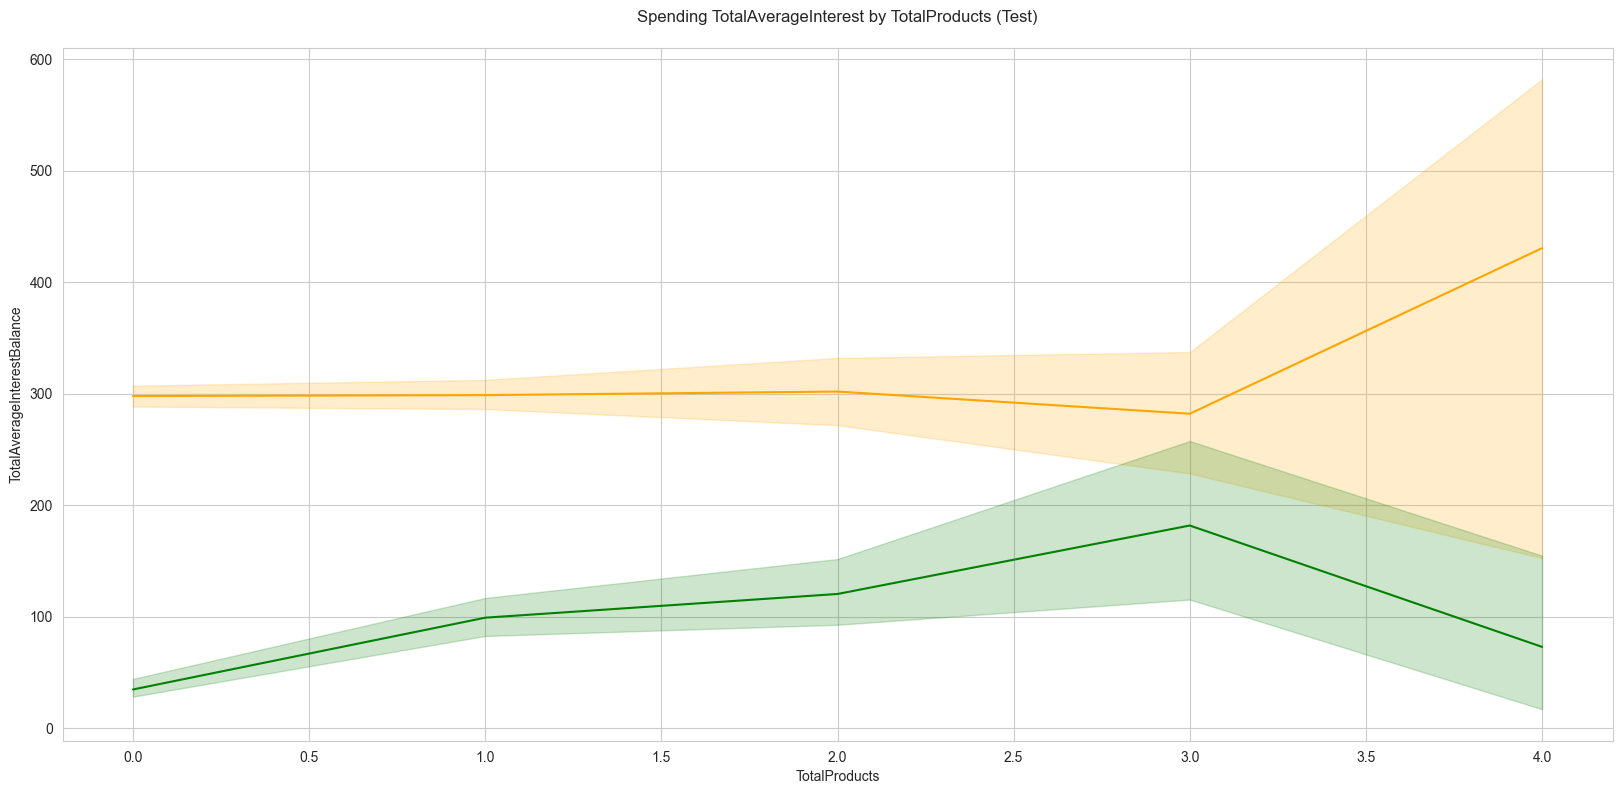

In [25]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts",
    y="TotalAverageInterestBalance",
    color="orange",
    data=df_test,
    ax=ax,
)
sns.lineplot(
    x="TotalProducts", y="TotalAverageInterest", color="green", data=df_test, ax=ax
)
plt.title("Spending TotalAverageInterest by TotalProducts (Test)\n")
plt.show()

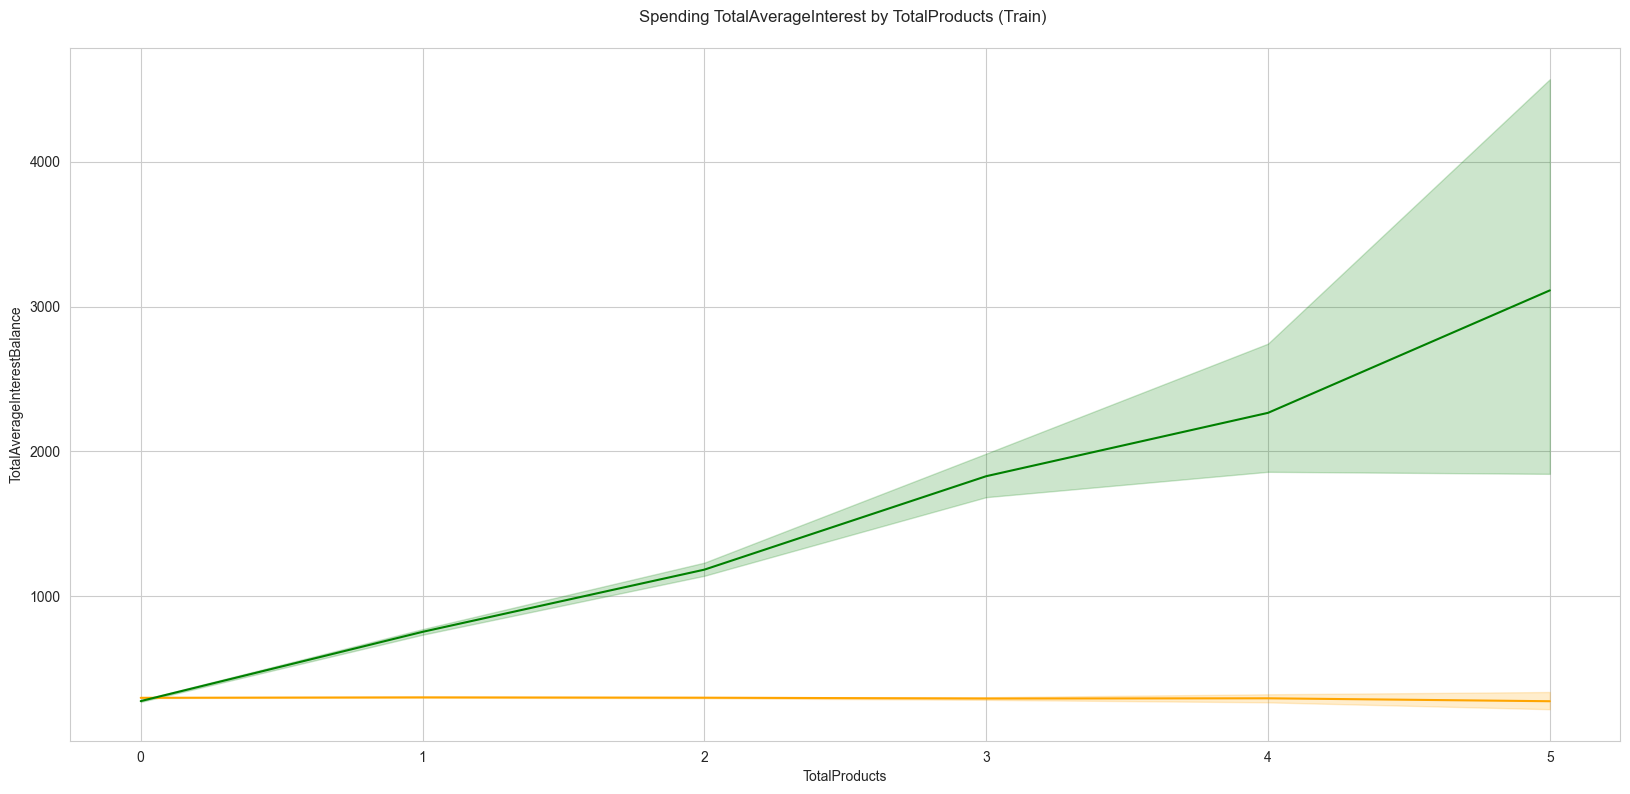

In [26]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts",
    y="TotalAverageInterestBalance",
    color="orange",
    data=df_train,
    ax=ax,
)
sns.lineplot(
    x="TotalProducts", y="TotalAverageInterest", color="green", data=df_train, ax=ax
)
plt.title("Spending TotalAverageInterest by TotalProducts (Train) \n")
plt.show()

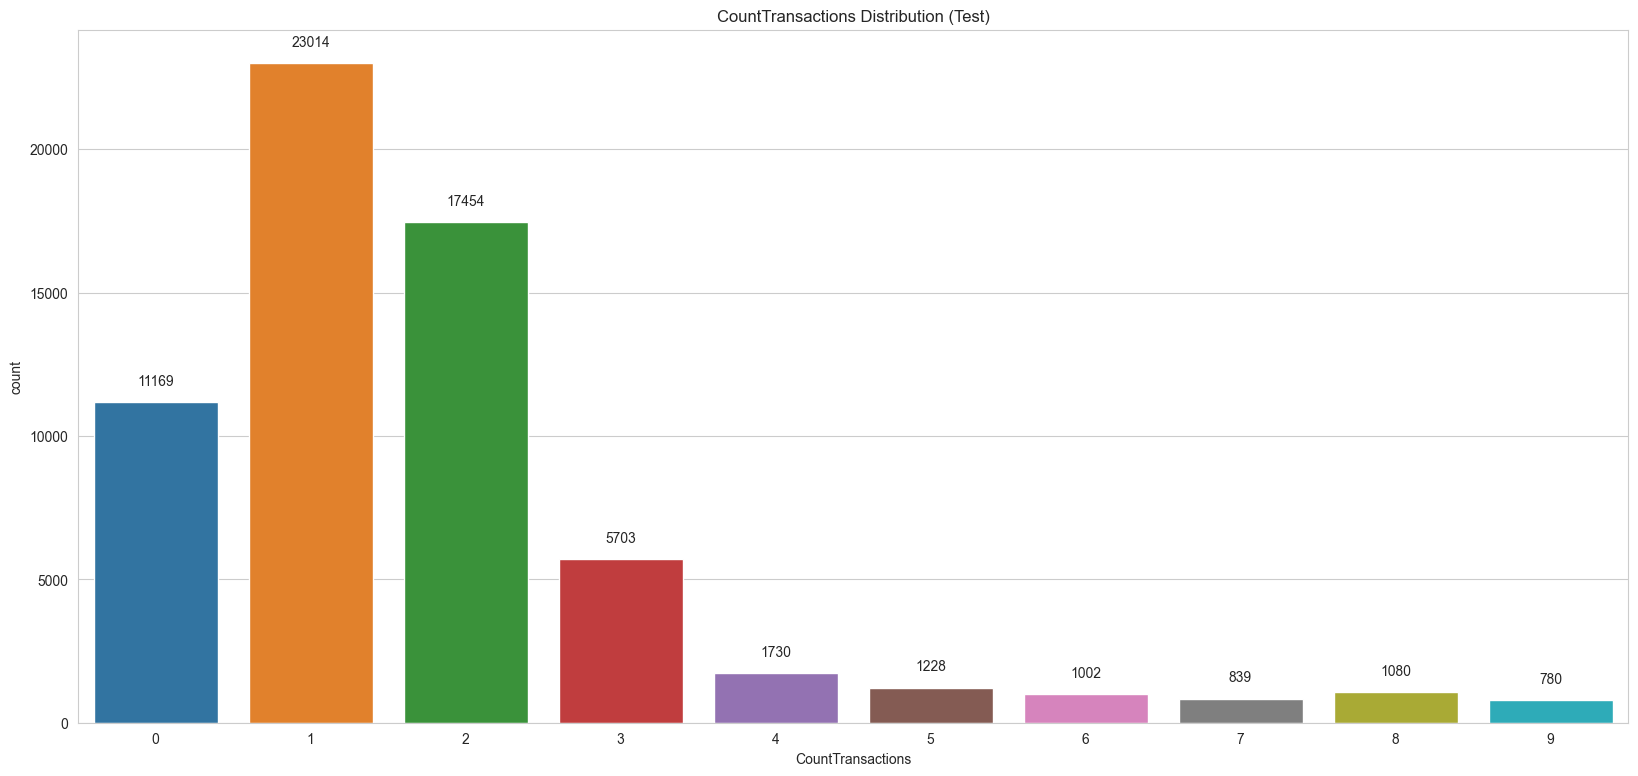

In [27]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="CountTransactions", data=df_train, ax=ax)
plt.title("CountTransactions Distribution (Test)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

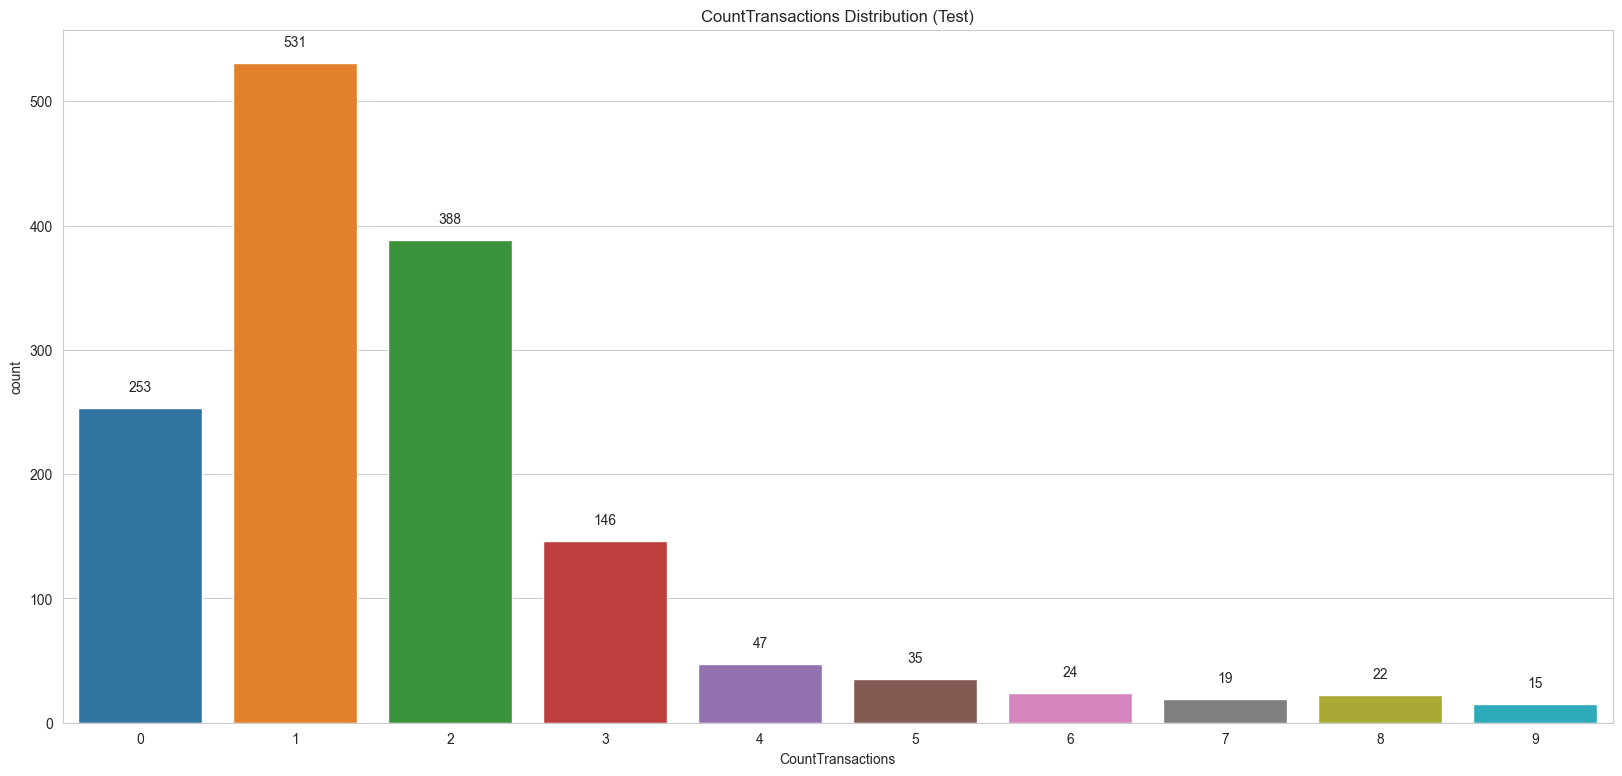

In [28]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="CountTransactions", data=df_test, ax=ax)
plt.title("CountTransactions Distribution (Test)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

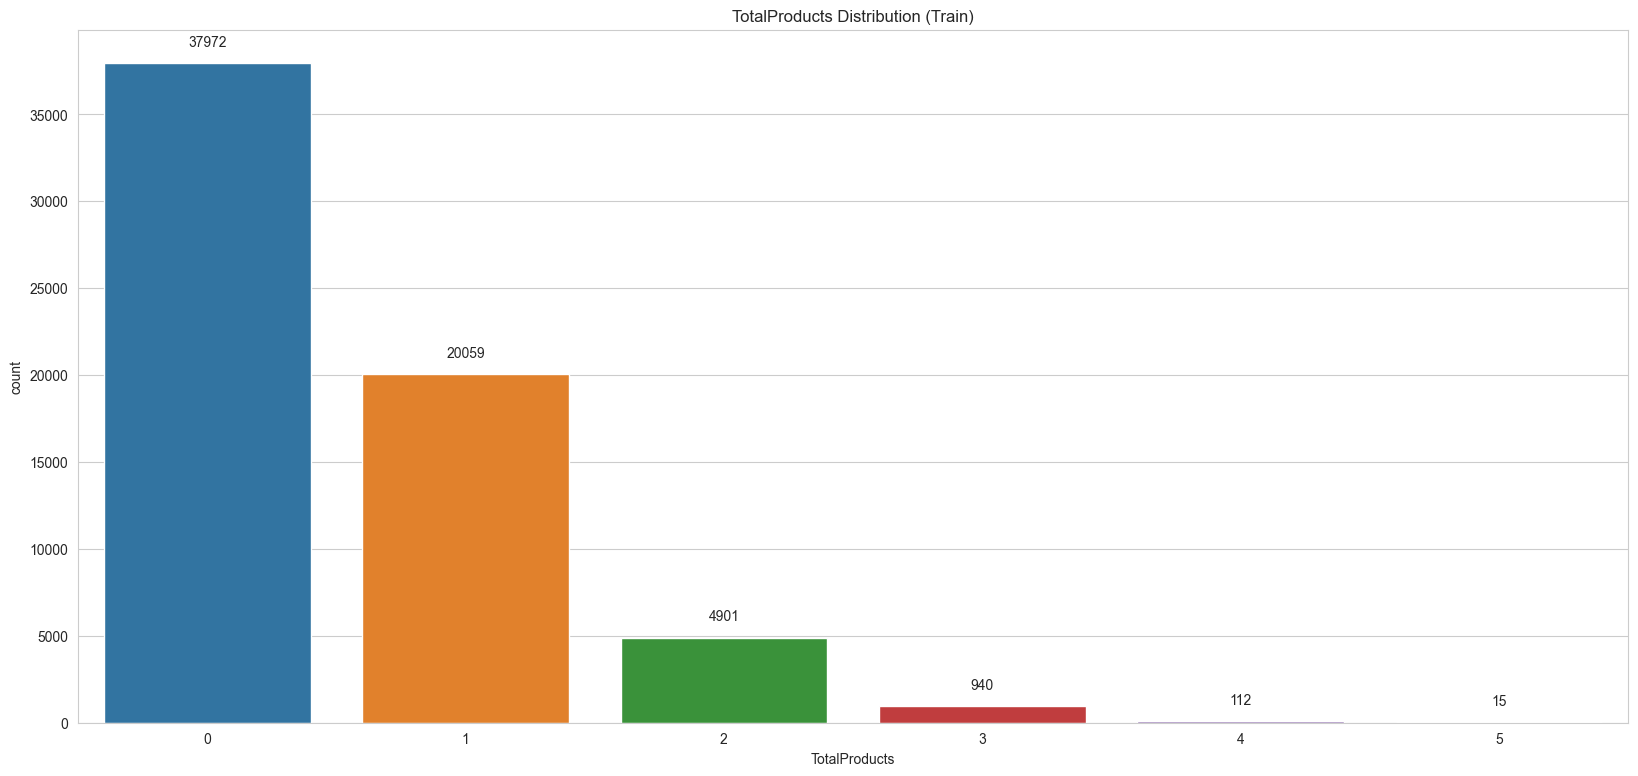

In [29]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="TotalProducts", data=df_train, ax=ax)
plt.title("TotalProducts Distribution (Train)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

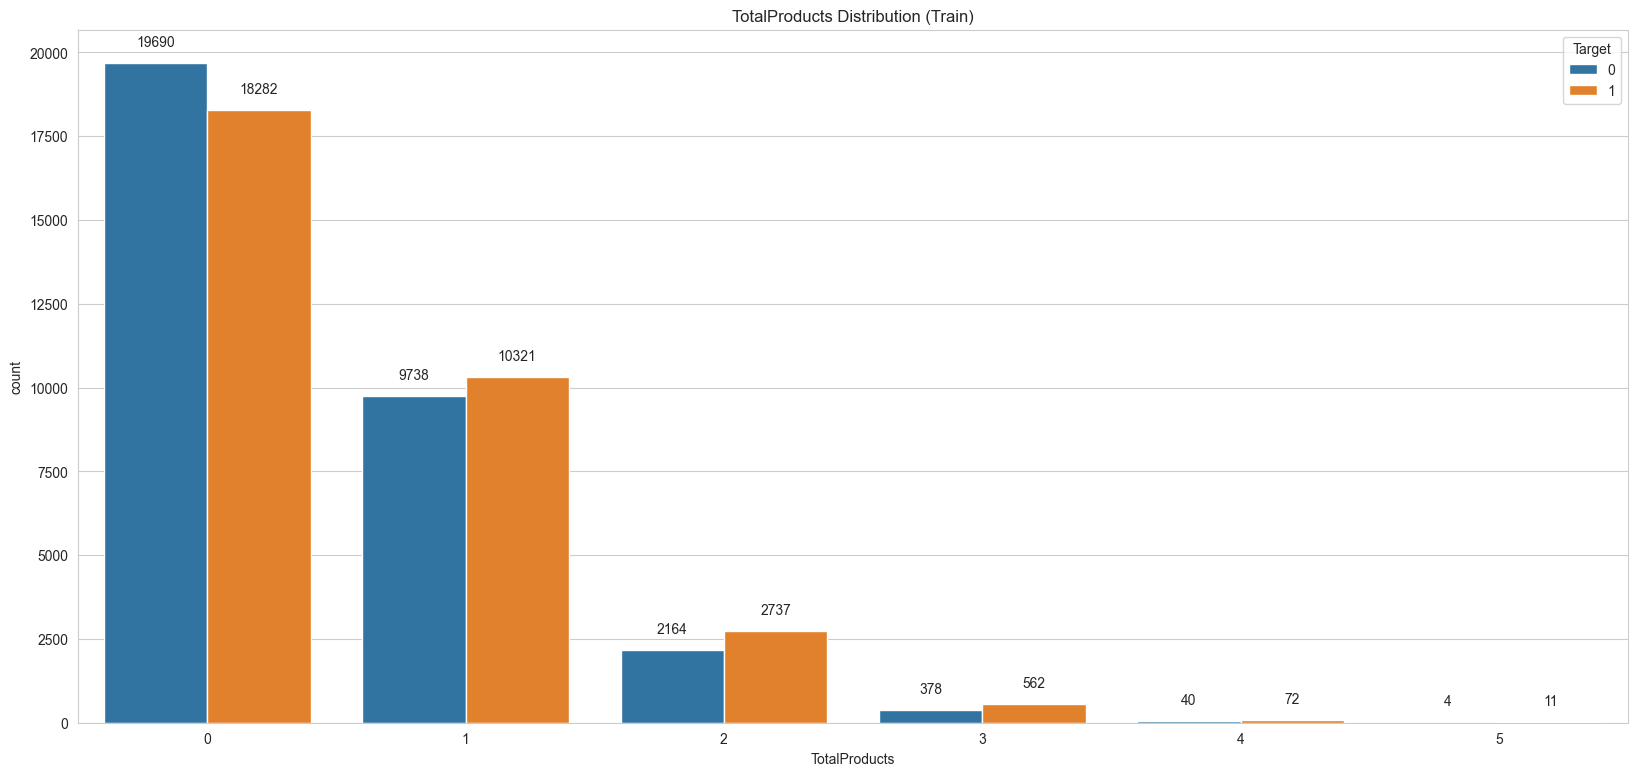

In [30]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="TotalProducts", hue="Target", data=df_train, ax=ax)
plt.title("TotalProducts Distribution (Train)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

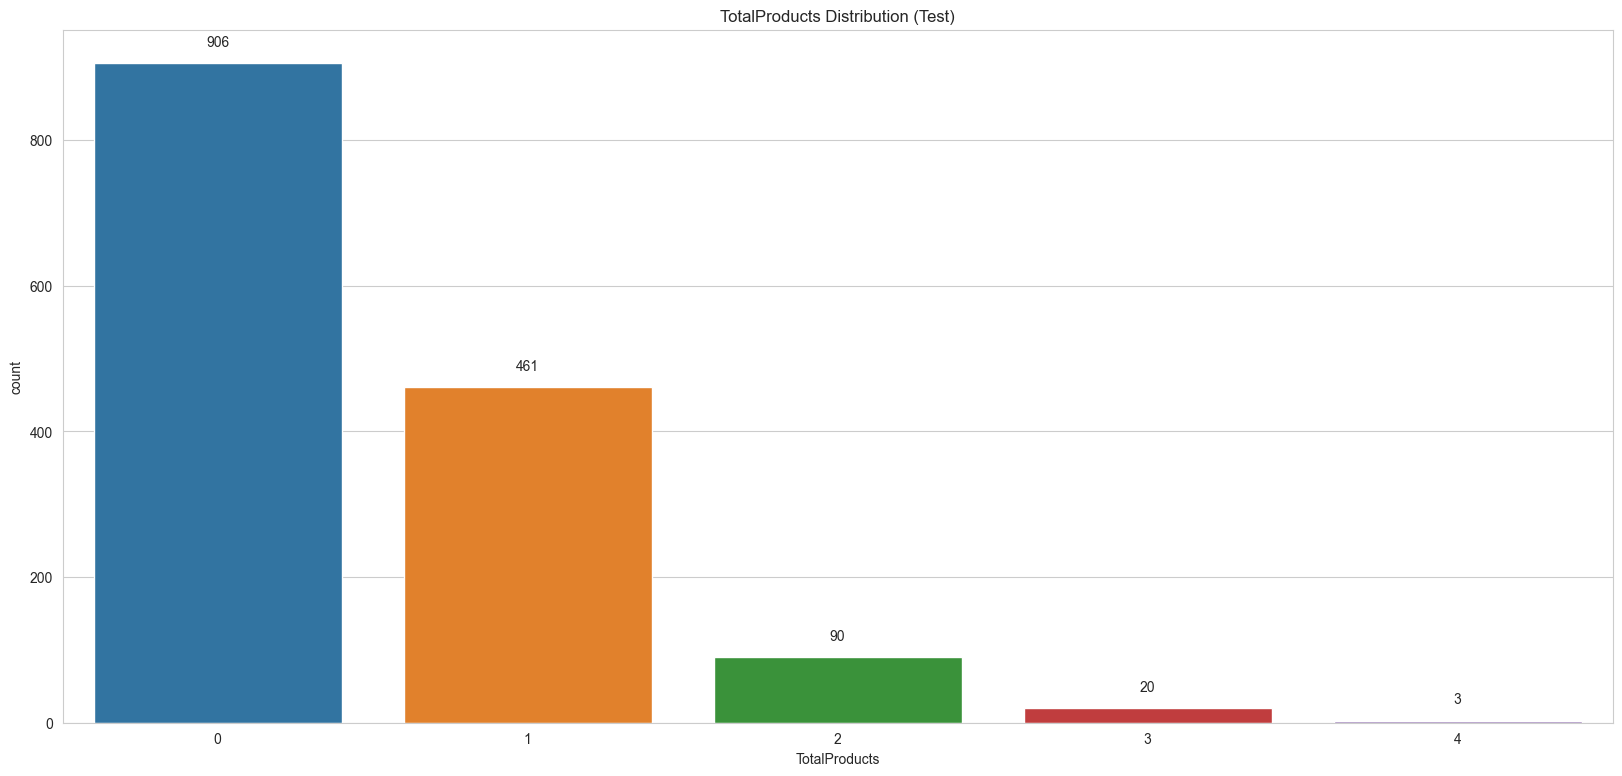

In [31]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="TotalProducts", data=df_test, ax=ax)
plt.title("TotalProducts Distribution (Test)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

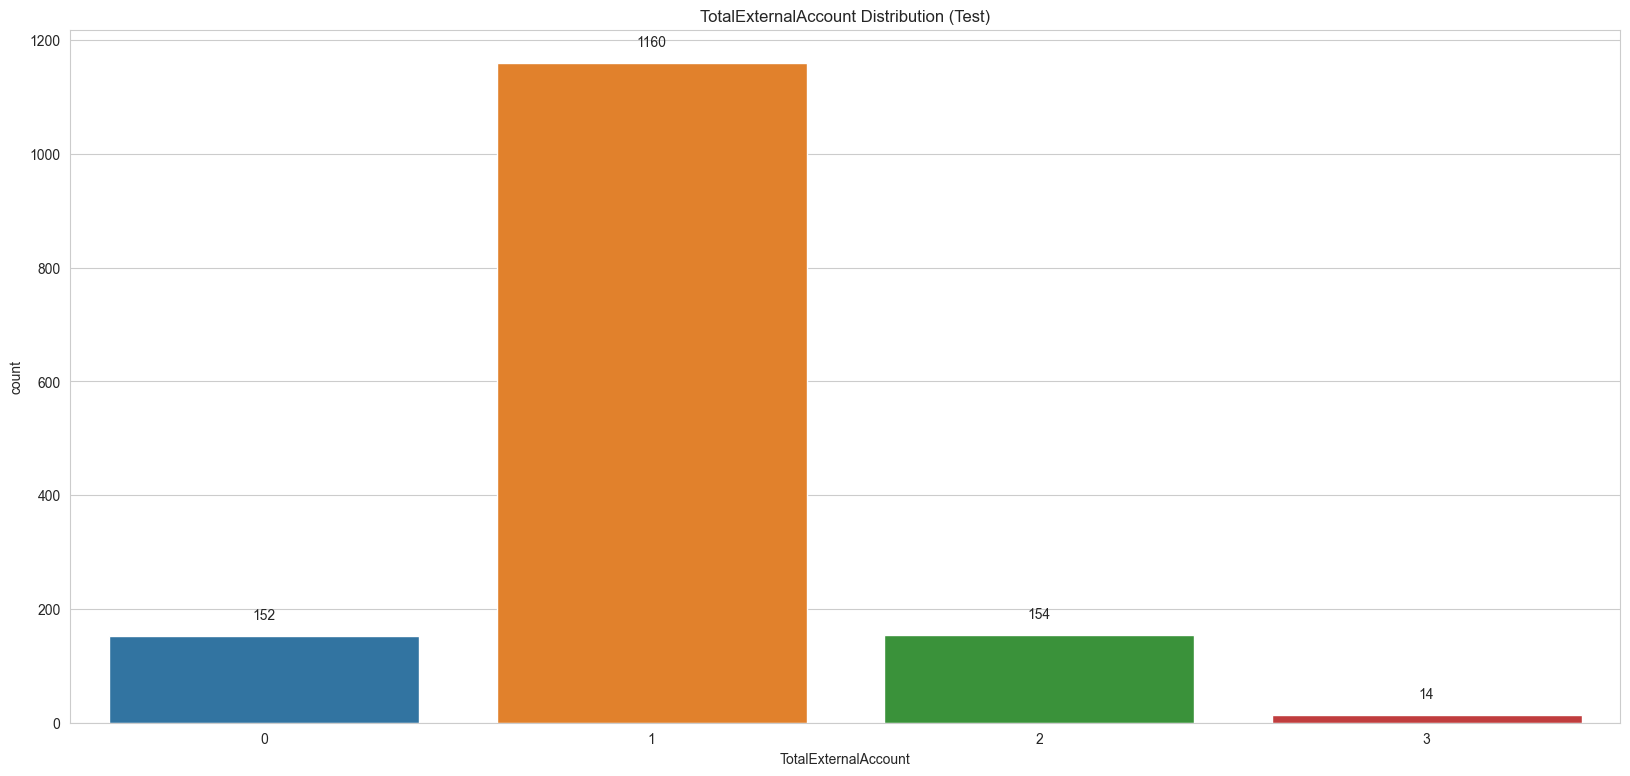

In [32]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="TotalExternalAccount", data=df_test, ax=ax)
plt.title("TotalExternalAccount Distribution (Test)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

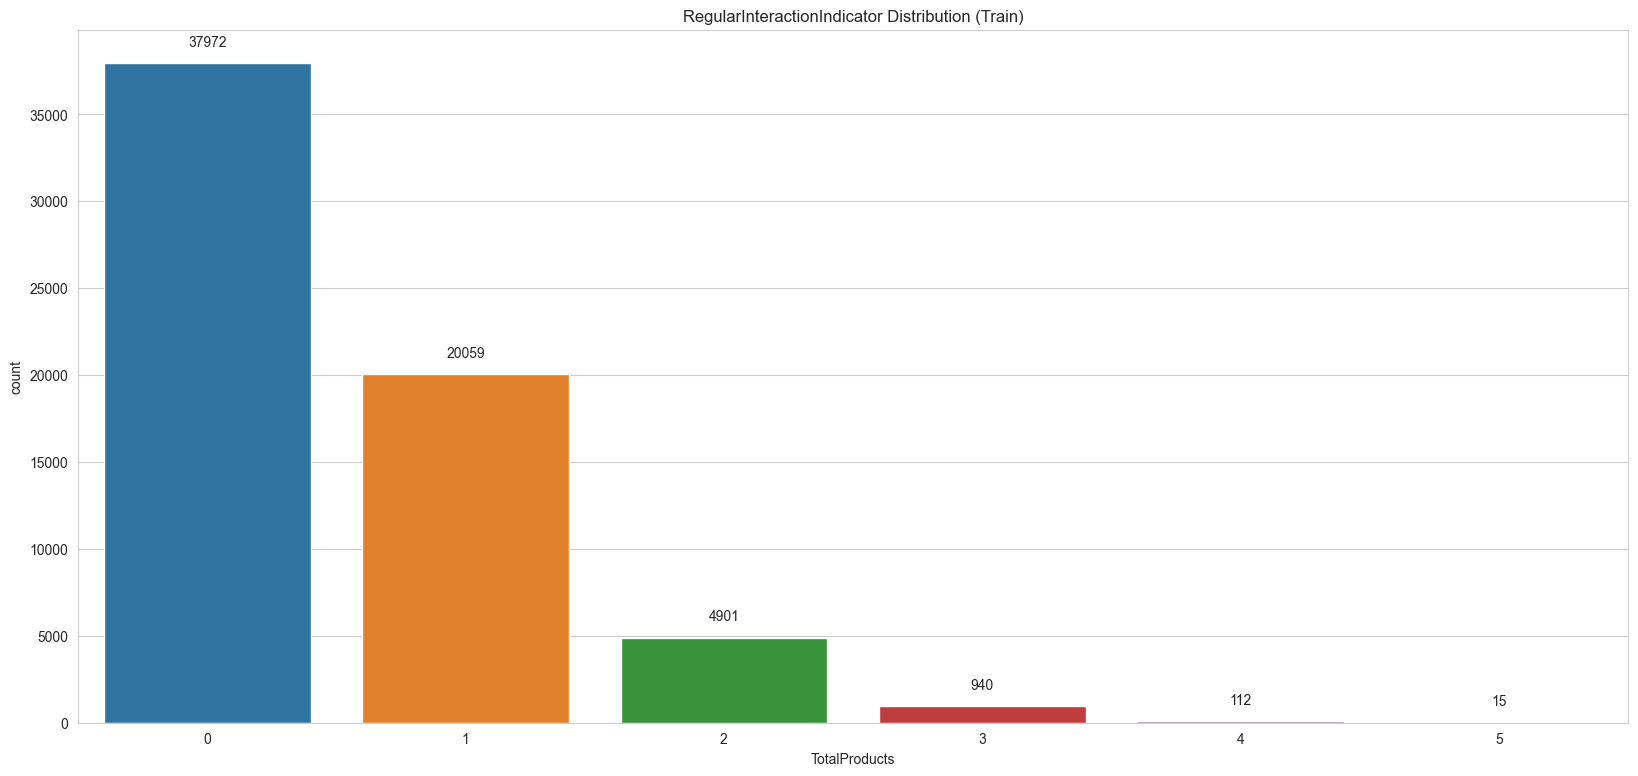

In [33]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="TotalProducts", data=df_train, ax=ax)
plt.title("RegularInteractionIndicator Distribution (Train)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

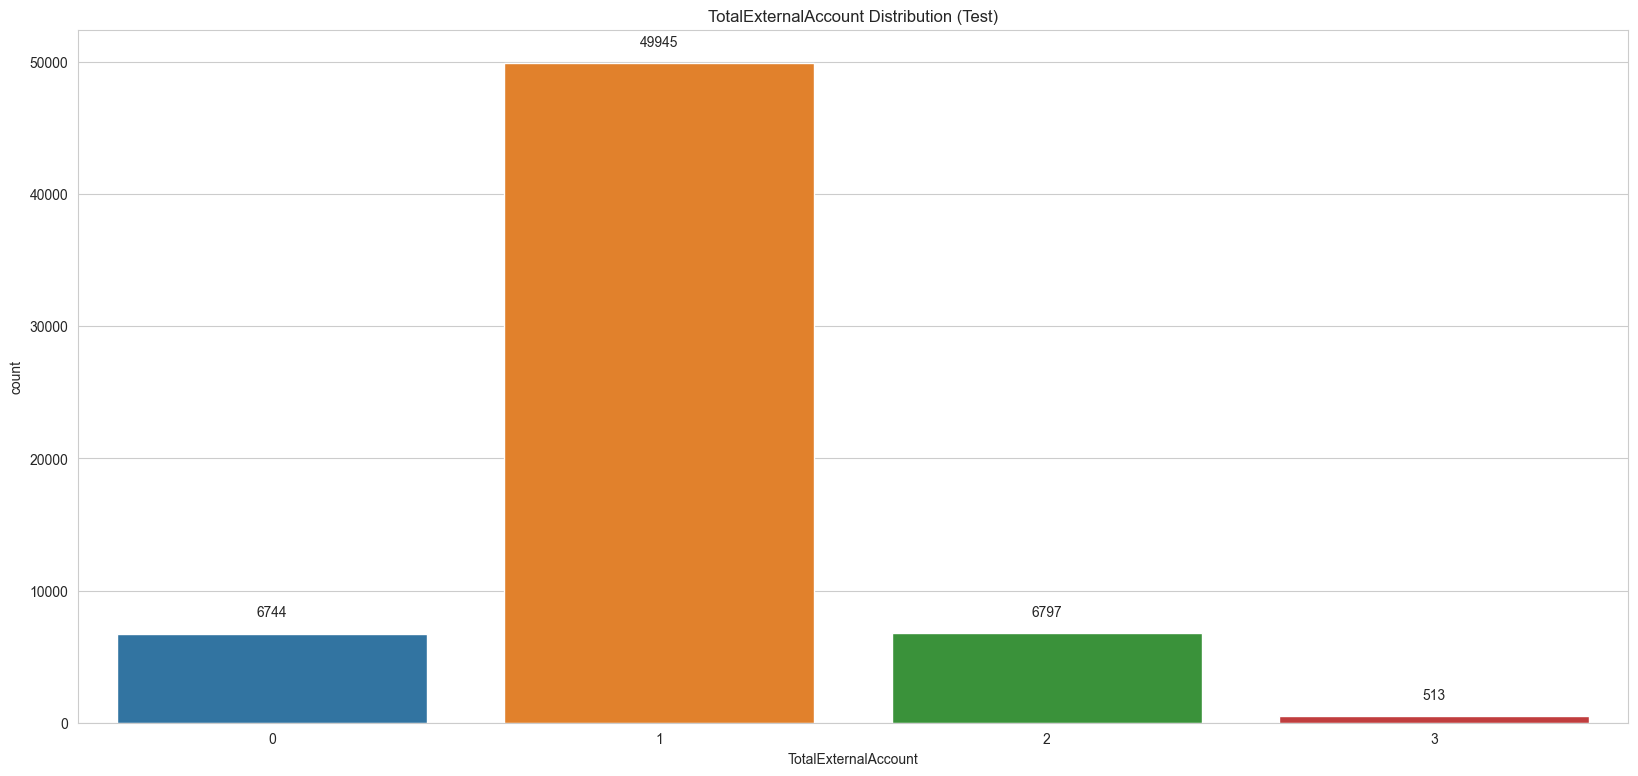

In [34]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="TotalExternalAccount", data=df_train, ax=ax)
plt.title("TotalExternalAccount Distribution (Test)")
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.show()

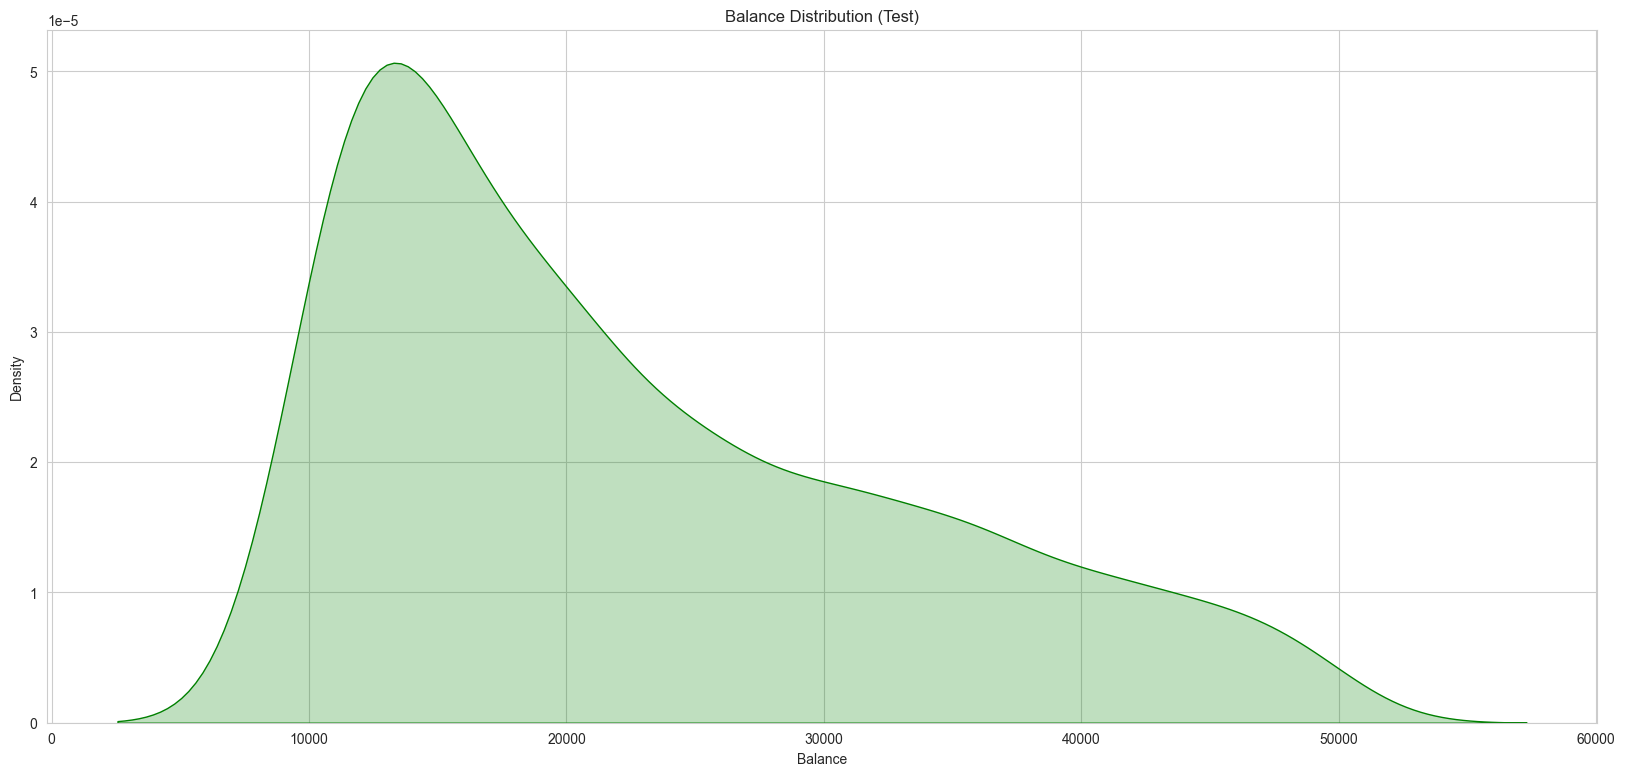

In [35]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.kdeplot(x="Balance", data=df_test, color="green", fill=True, ax=ax)
plt.title("Balance Distribution (Test)")
plt.show()

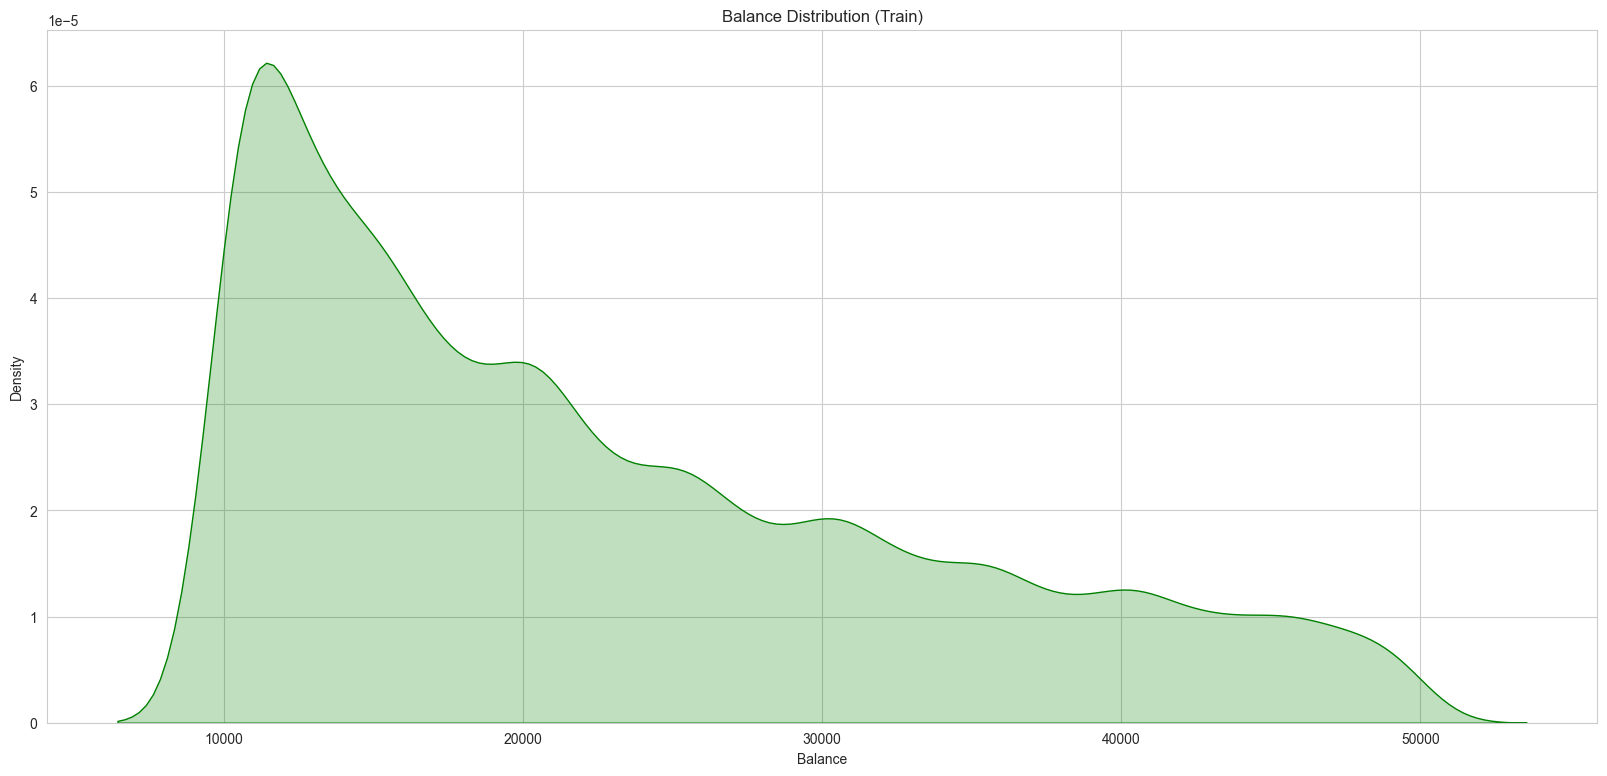

In [36]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.kdeplot(x="Balance", data=df_train, color="green", fill=True, ax=ax)
plt.title("Balance Distribution (Train)")
plt.show()

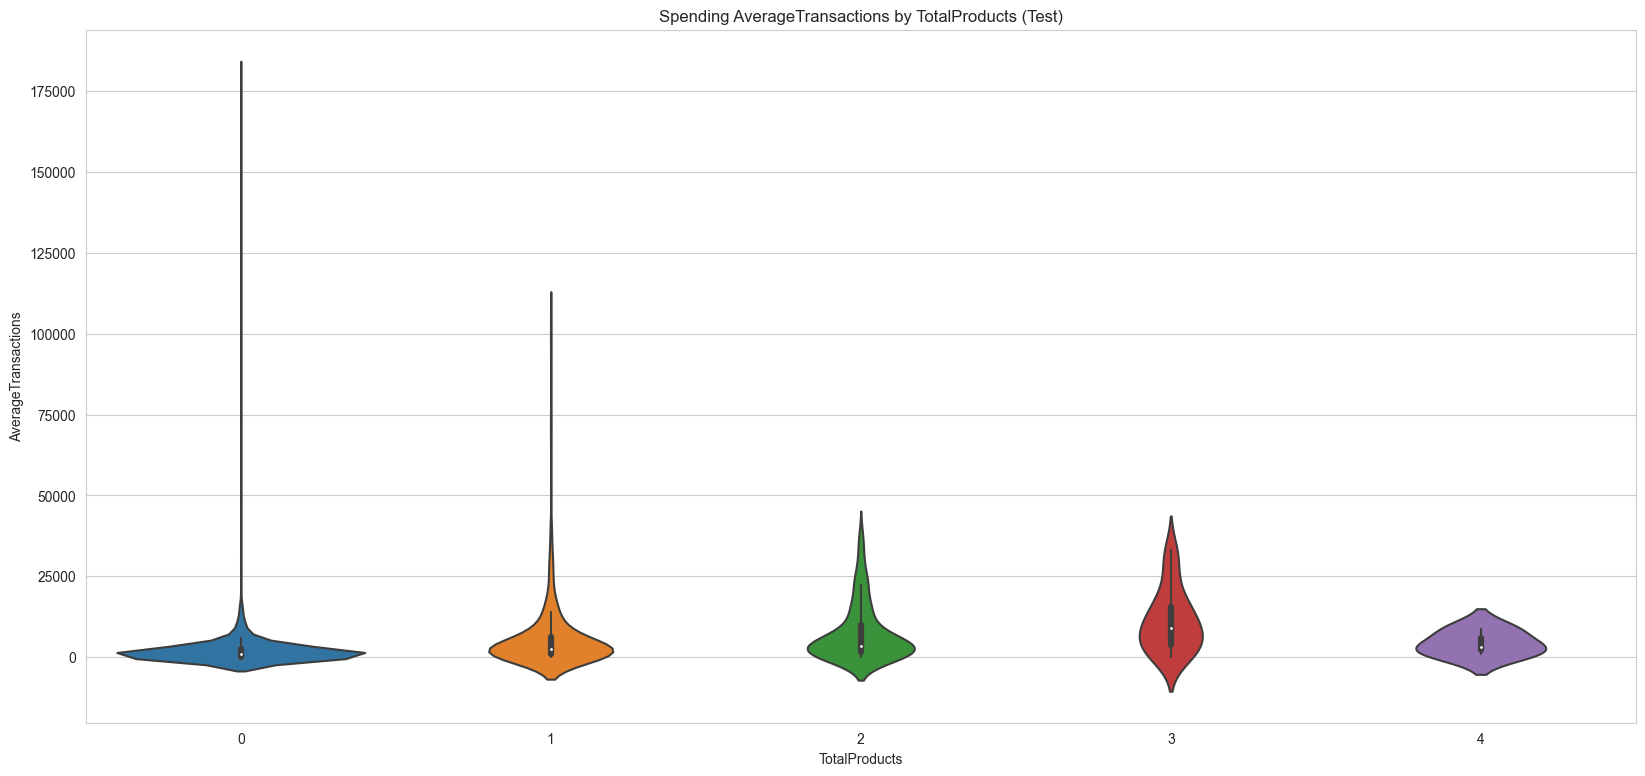

In [37]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.violinplot(x="TotalProducts", y="AverageTransactions", data=df_test, ax=ax)
plt.title("Spending AverageTransactions by TotalProducts (Test)")
plt.show()

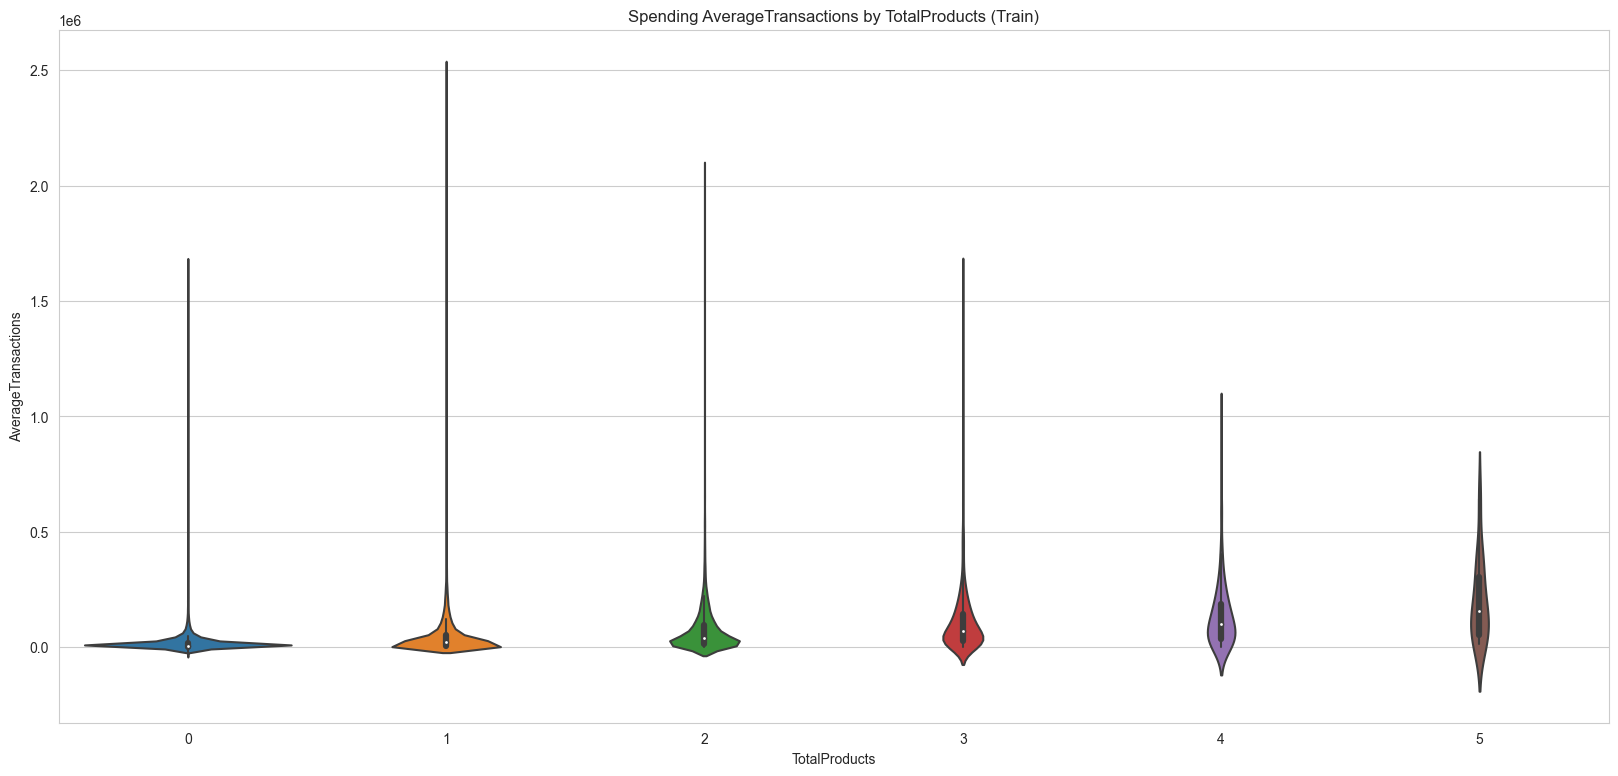

In [38]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.violinplot(x="TotalProducts", y="AverageTransactions", data=df_train, ax=ax)
plt.title("Spending AverageTransactions by TotalProducts (Train)")
plt.show()

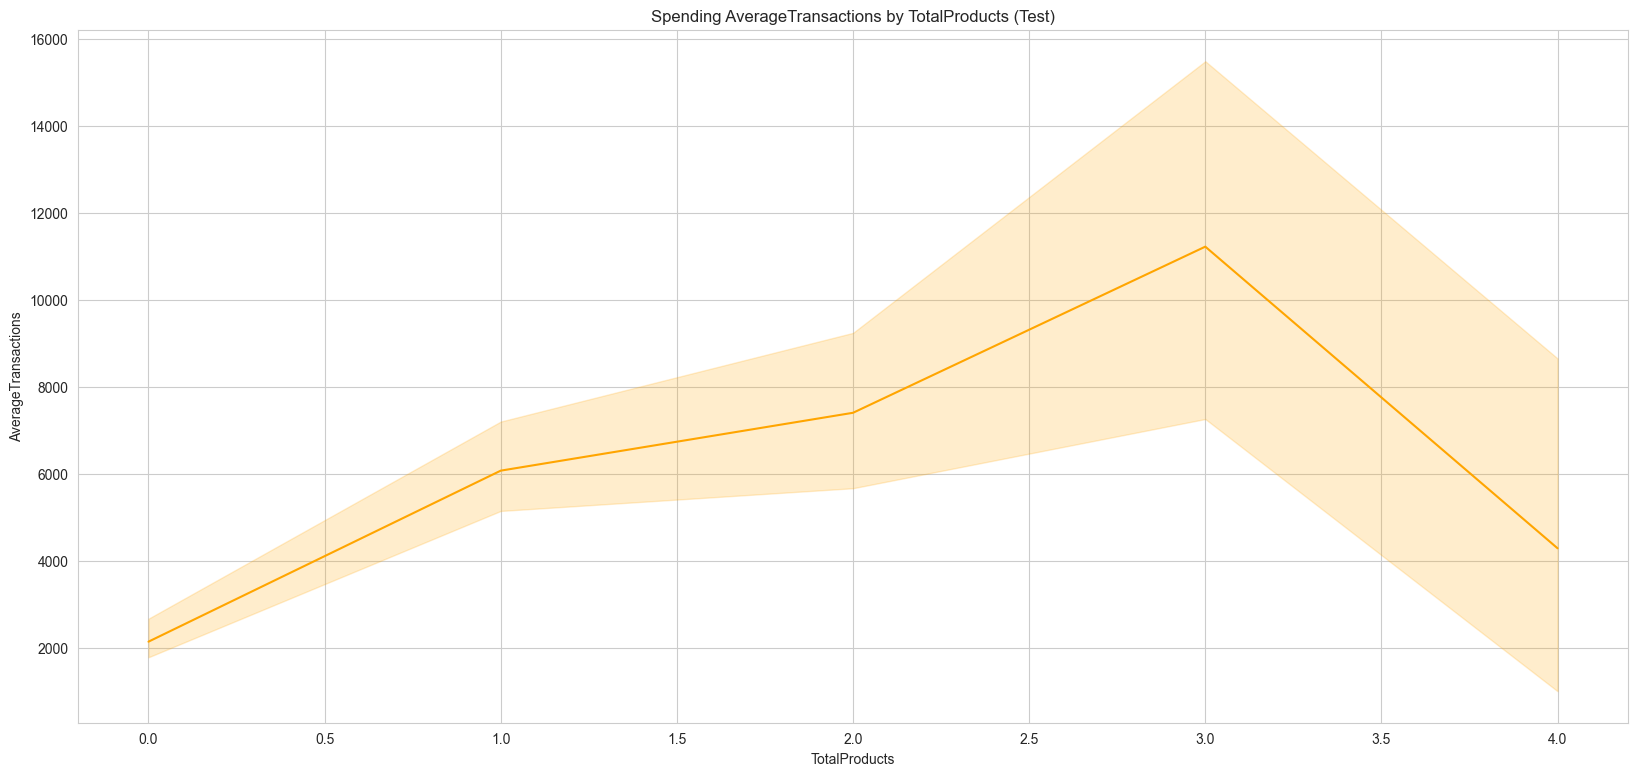

In [39]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts", y="AverageTransactions", color="orange", data=df_test, ax=ax
)
plt.title("Spending AverageTransactions by TotalProducts (Test)")
plt.show()

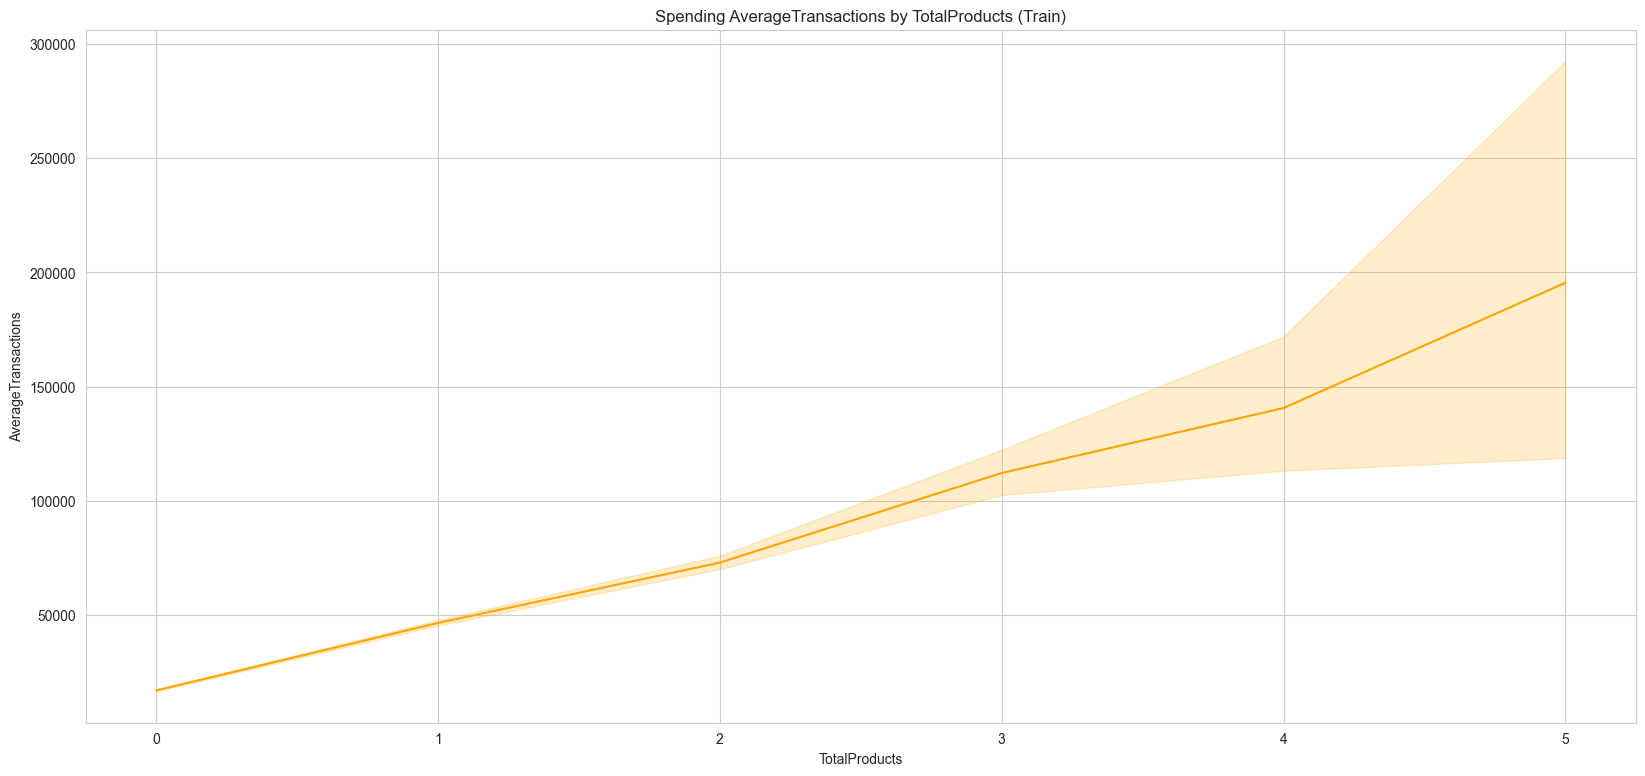

In [40]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts", y="AverageTransactions", color="orange", data=df_train, ax=ax
)
plt.title("Spending AverageTransactions by TotalProducts (Train)")
plt.show()

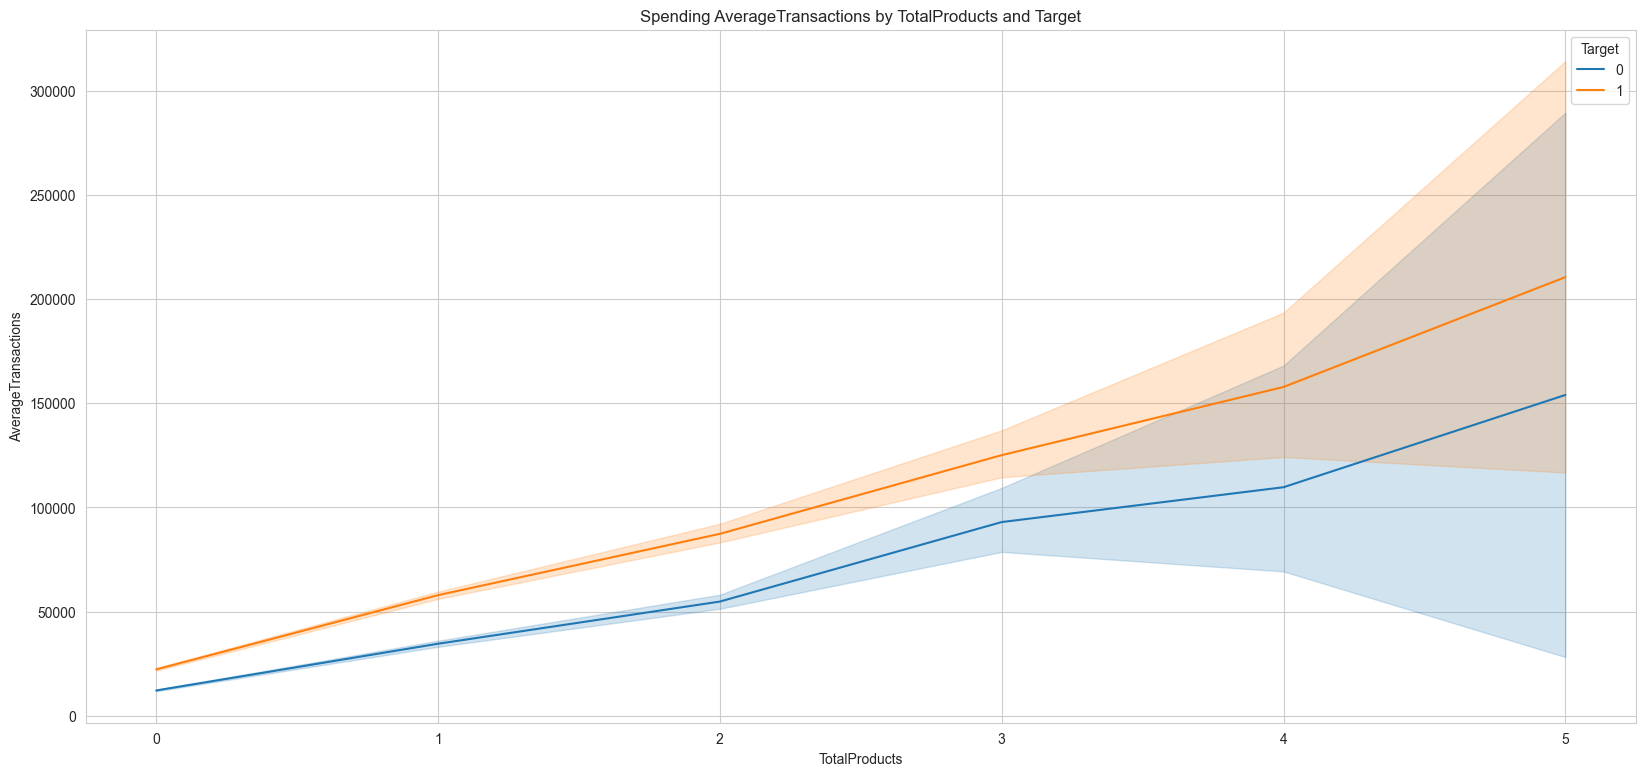

In [41]:
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x="TotalProducts", y="AverageTransactions", hue="Target", data=df_train, ax=ax
)
plt.title("Spending AverageTransactions by TotalProducts and Target")
plt.show()

<Axes: >

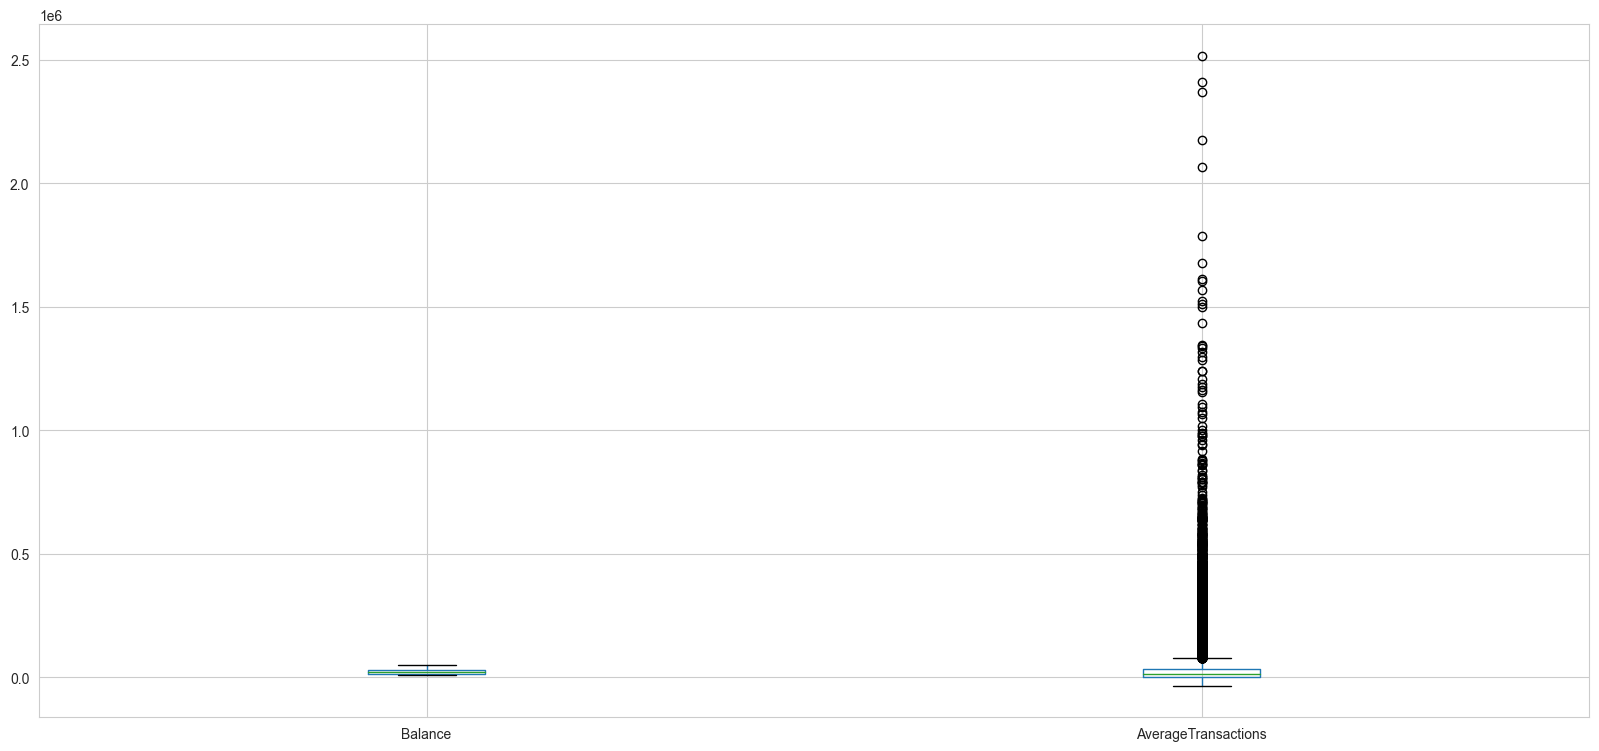

In [42]:
# distribution of the continuous variables
fig, ax = plt.subplots(figsize=(20, 9))
df_train.boxplot(
    column=["Balance", "AverageTransactions"],
    ax=ax,
)

<Axes: >

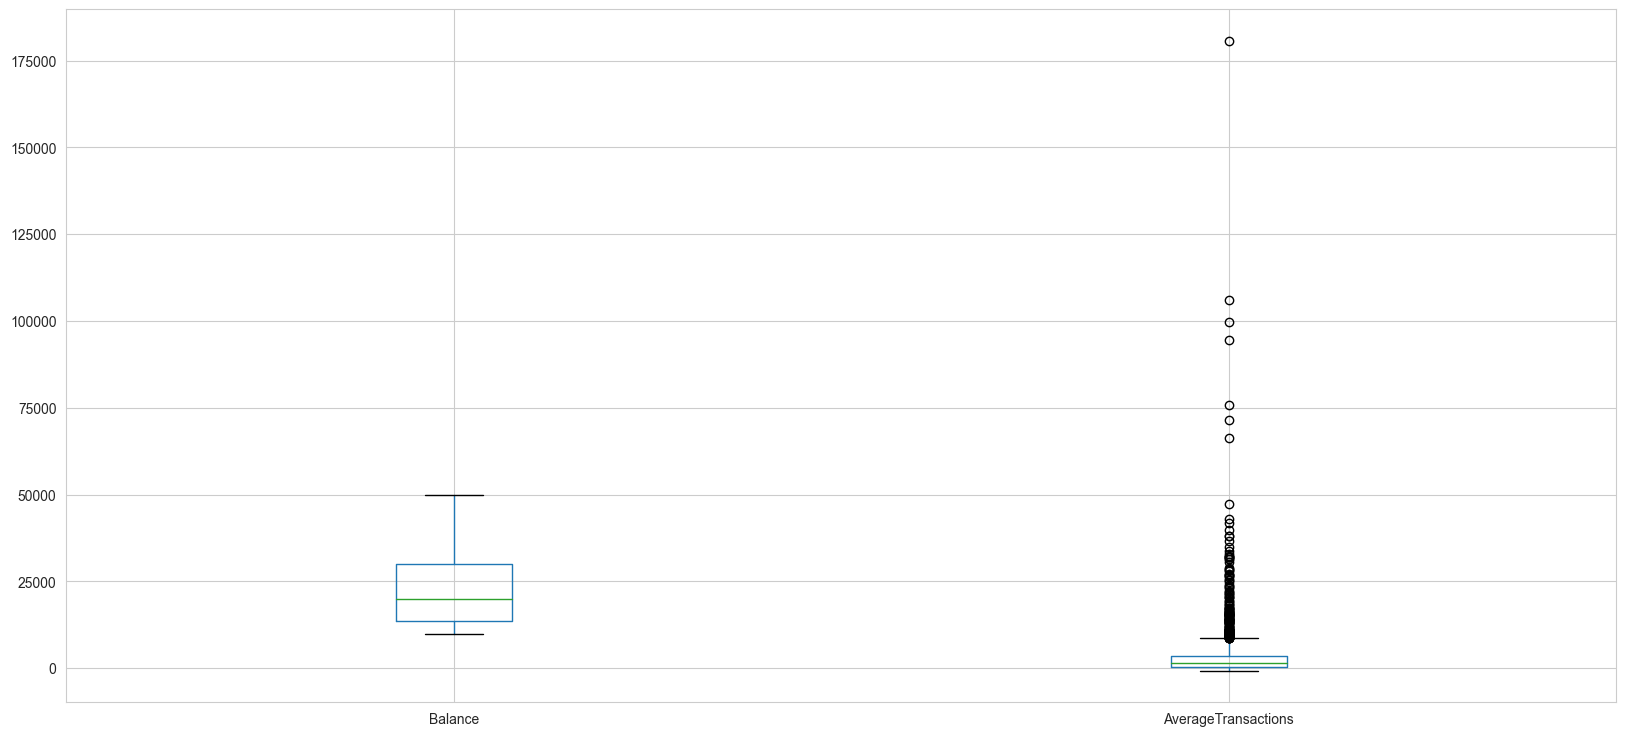

In [43]:
fig, ax = plt.subplots(figsize=(20, 9))
df_test.boxplot(
    column=["Balance", "AverageTransactions"],
    ax=ax,
)

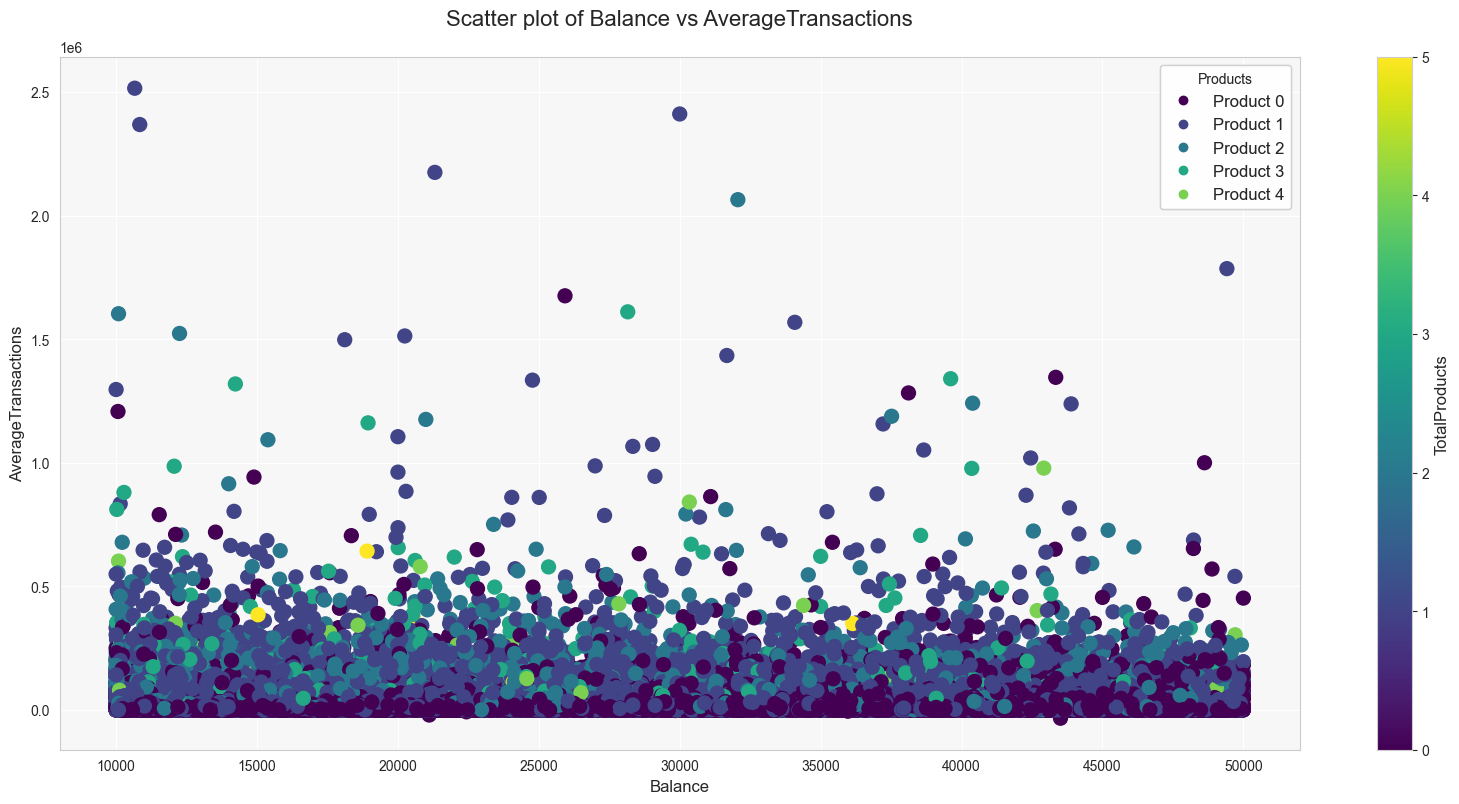

In [44]:
fig, ax = plt.subplots(figsize=(20, 9))
scatter = ax.scatter(
    df_train["Balance"],
    df_train["AverageTransactions"],
    c=df_train["TotalProducts"],
    cmap="viridis",
    s=100,
)

# Add labels and title
ax.set_xlabel("Balance", fontsize=12)
ax.set_ylabel("AverageTransactions", fontsize=12)
ax.set_title("Scatter plot of Balance vs AverageTransactions\n", fontsize=16)

# Add colorbar legend
cbar = fig.colorbar(scatter)
cbar.set_label("TotalProducts", fontsize=12)

# Set tick labels font size
ax.tick_params(axis="both", labelsize=10)

# Set plot background color and grid
ax.set_facecolor("#f7f7f7")
ax.grid(color="white")

# Create dictionary to map codes to species names
total_products_dict = {
    0: "Product 0",
    1: "Product 1",
    2: "Product 2",
    3: "Product 3",
    4: "Product 4",
}

# Add legend with species names
legend_handles, _ = scatter.legend_elements()
legend_labels = [
    total_products_dict[code] for code in df_test["TotalProducts"].unique()
]
legend = ax.legend(legend_handles, legend_labels, title="Products", fontsize=12)
ax.add_artist(legend)

# Show plot
plt.show()

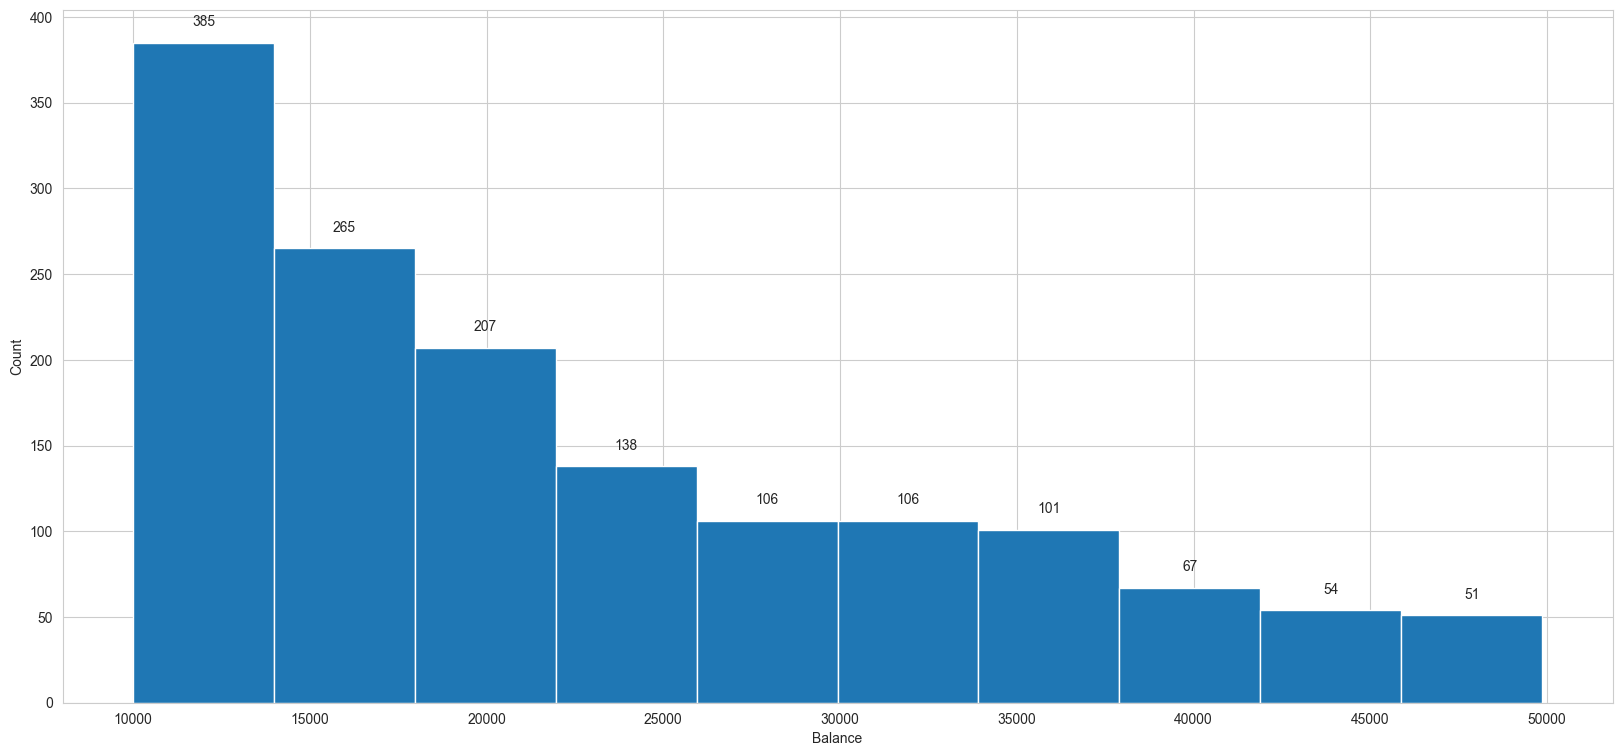

In [45]:
# Histogram
fig, ax = plt.subplots(figsize=(20, 9))
plt.hist(df_test["Balance"])
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.xlabel("Balance")
plt.ylabel("Count")
plt.show()

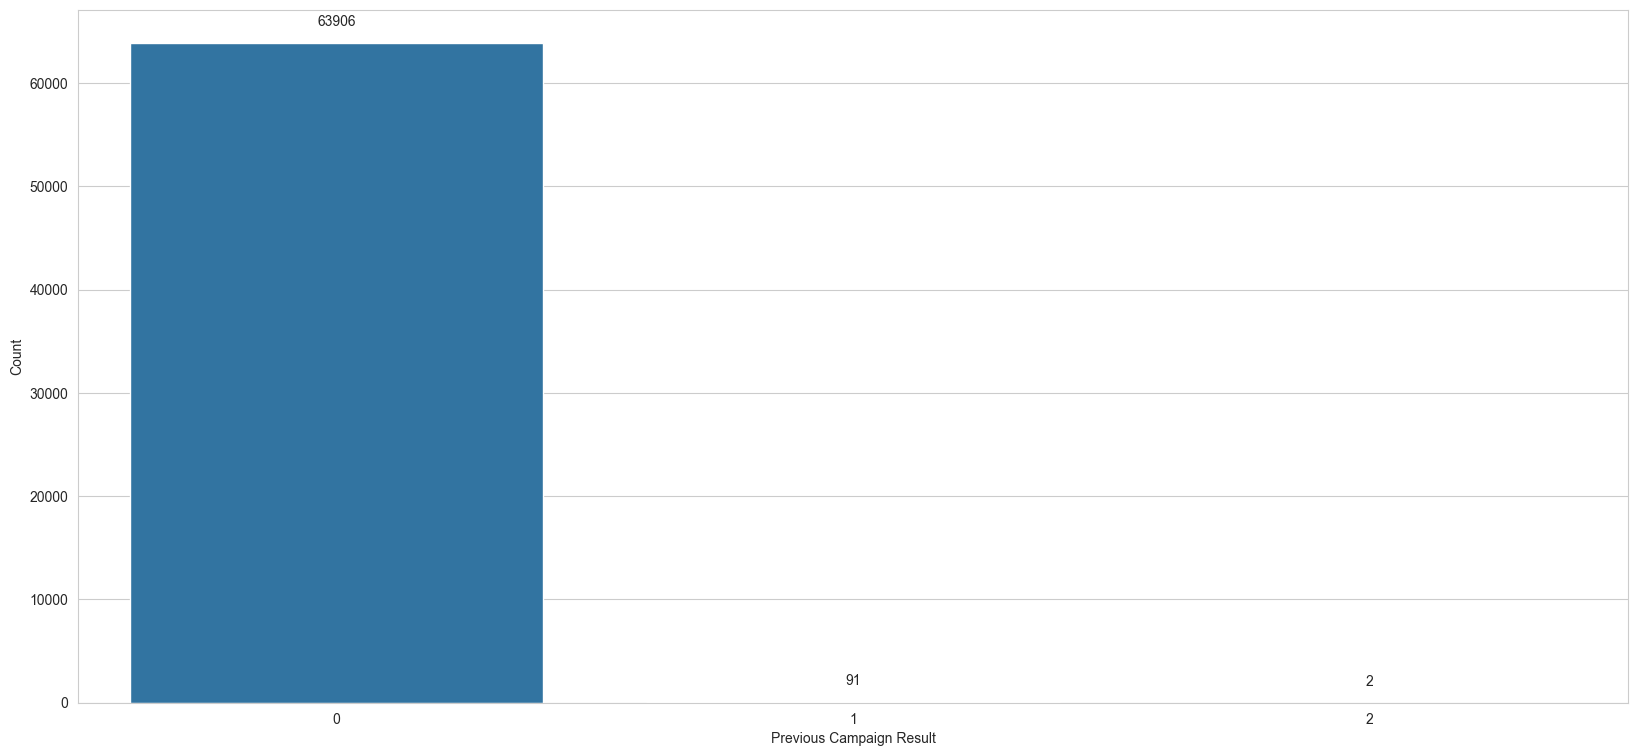

In [46]:
# Bar Chart
fig, ax = plt.subplots(figsize=(20, 9))
sns.countplot(x="PreviousCampaignResult", data=df_train, ax=ax)
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.xlabel("Previous Campaign Result")
plt.ylabel("Count")
plt.show()

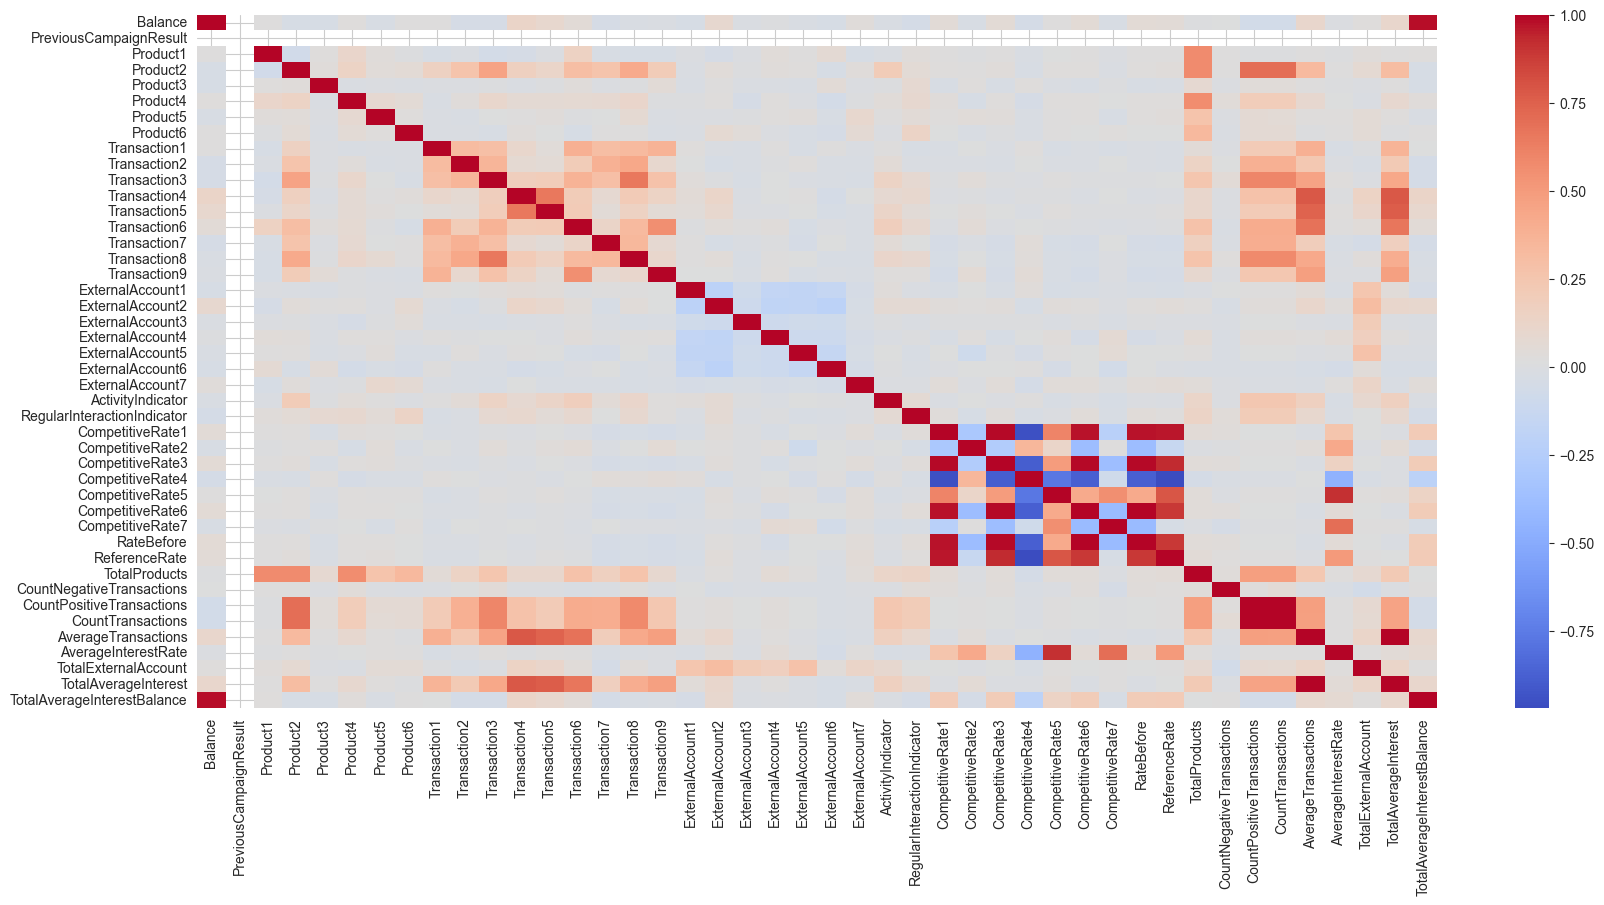

In [47]:
# Heatmap
corr = df_test.corr()
fig, ax = plt.subplots(figsize=(20, 9))
sns.heatmap(corr, cmap="coolwarm", ax=ax)
plt.show()

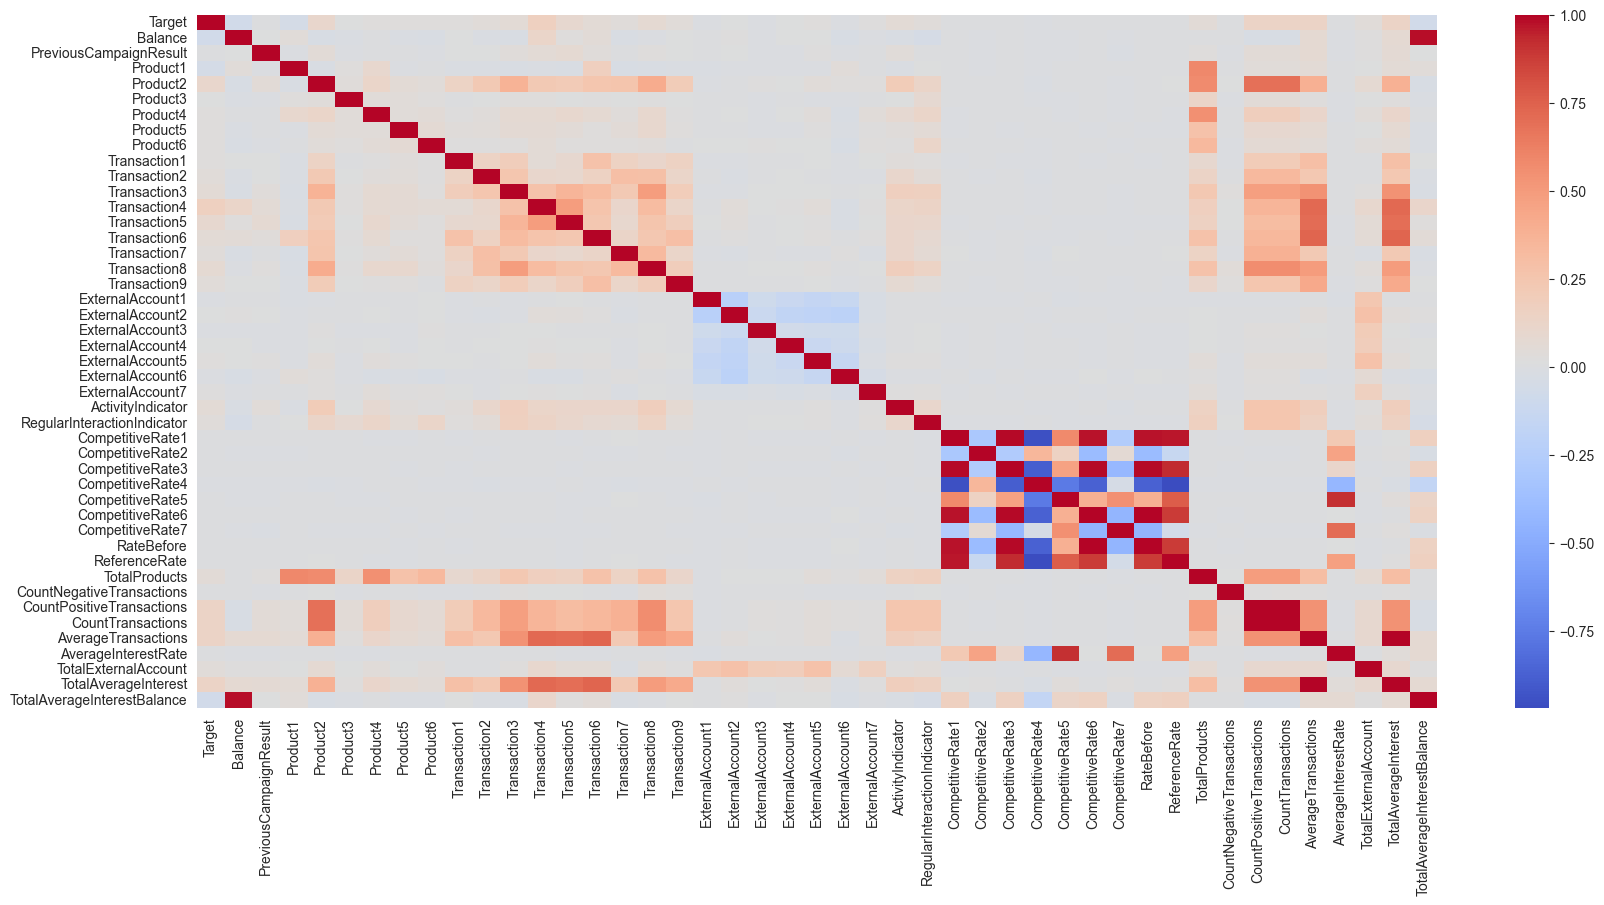

In [48]:
corr = df_train.corr()
fig, ax = plt.subplots(figsize=(20, 9))
sns.heatmap(corr, cmap="coolwarm", ax=ax)
plt.show()

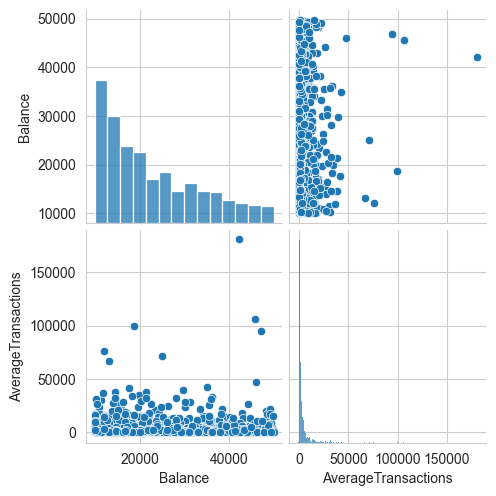

In [49]:
# Pair Plot
sns.pairplot(df_test, vars=["Balance", "AverageTransactions"])
plt.show()

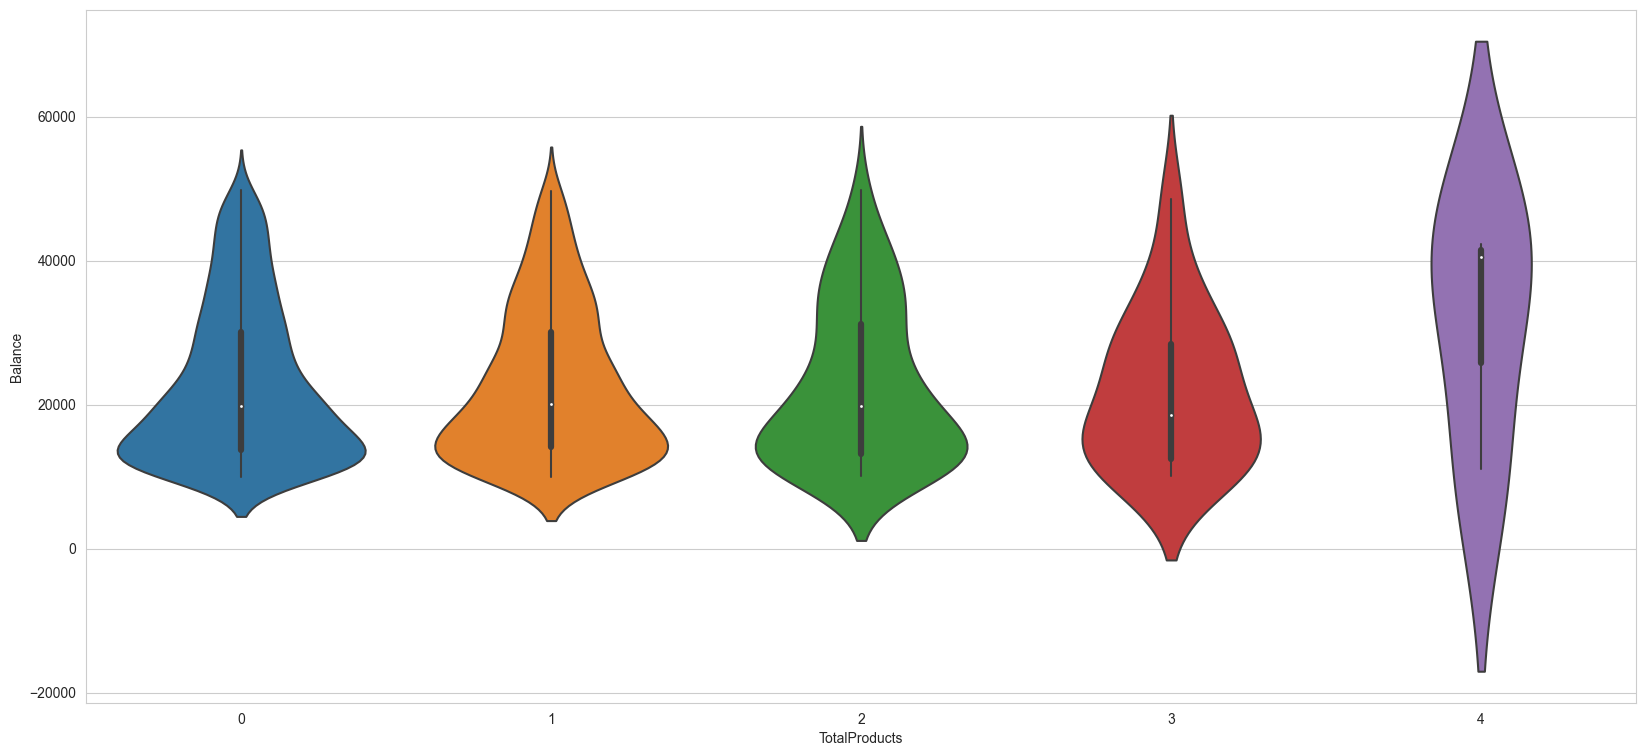

In [50]:
# Violin Plot
fig, ax = plt.subplots(figsize=(20, 9))
sns.violinplot(x="TotalProducts", y="Balance", data=df_test, ax=ax)
plt.xlabel("TotalProducts")
plt.ylabel("Balance")
plt.show()

# Cleansing

In [51]:
list_products = df_train.loc[
    :, df_train.columns.str.startswith("Product")
].columns.values
df_train_cleaned = df_train.copy()

In [53]:
for item in tqdm_notebook(list_products, desc="Products"):
    df_item = df_train_cleaned[df_train_cleaned[item] > 0]["AverageTransactions"]
    outlier_data = OutliersData(df_item)

    outliers = outlier_data.zr_score_outlier()
    outliers += outlier_data.z_score_outlier()
    outliers += outlier_data.iqr_outliers()
    outliers += outlier_data.winsorization_outliers()
    outliers += outlier_data.db_outliers()
    outliers += outlier_data.iso_outliers()
    df_train_cleaned.drop(
        df_train_cleaned[
            (df_train_cleaned["AverageTransactions"].isin(outliers))
            & df_train_cleaned[item]
            > 0
        ].index,
        inplace=True,
    )

del df_item
del outliers
del outlier_data

Products:   0%|          | 0/6 [00:00<?, ?it/s]

In [54]:
for item in tqdm_notebook(list_products, desc="Products"):
    df_item = df_train_cleaned[df_train_cleaned[item] > 0]["Balance"]
    outlier_data = OutliersData(df_item)

    outliers = outlier_data.zr_score_outlier()
    outliers += outlier_data.z_score_outlier()
    outliers += outlier_data.iqr_outliers()
    outliers += outlier_data.winsorization_outliers()
    outliers += outlier_data.db_outliers()
    outliers += outlier_data.iso_outliers()
    df_train_cleaned.drop(
        df_train_cleaned[
            (df_train_cleaned["Balance"].isin(outliers)) & df_train_cleaned[item] > 0
        ].index,
        inplace=True,
    )

del df_item
del outliers
del outlier_data

Products:   0%|          | 0/6 [00:00<?, ?it/s]

In [55]:
df_train_cleaned = df_train_cleaned[df_train_cleaned["PreviousCampaignResult"] != 0]

In [56]:
df_train_cleaned.drop(columns=["PreviousCampaignResult"], inplace=True)

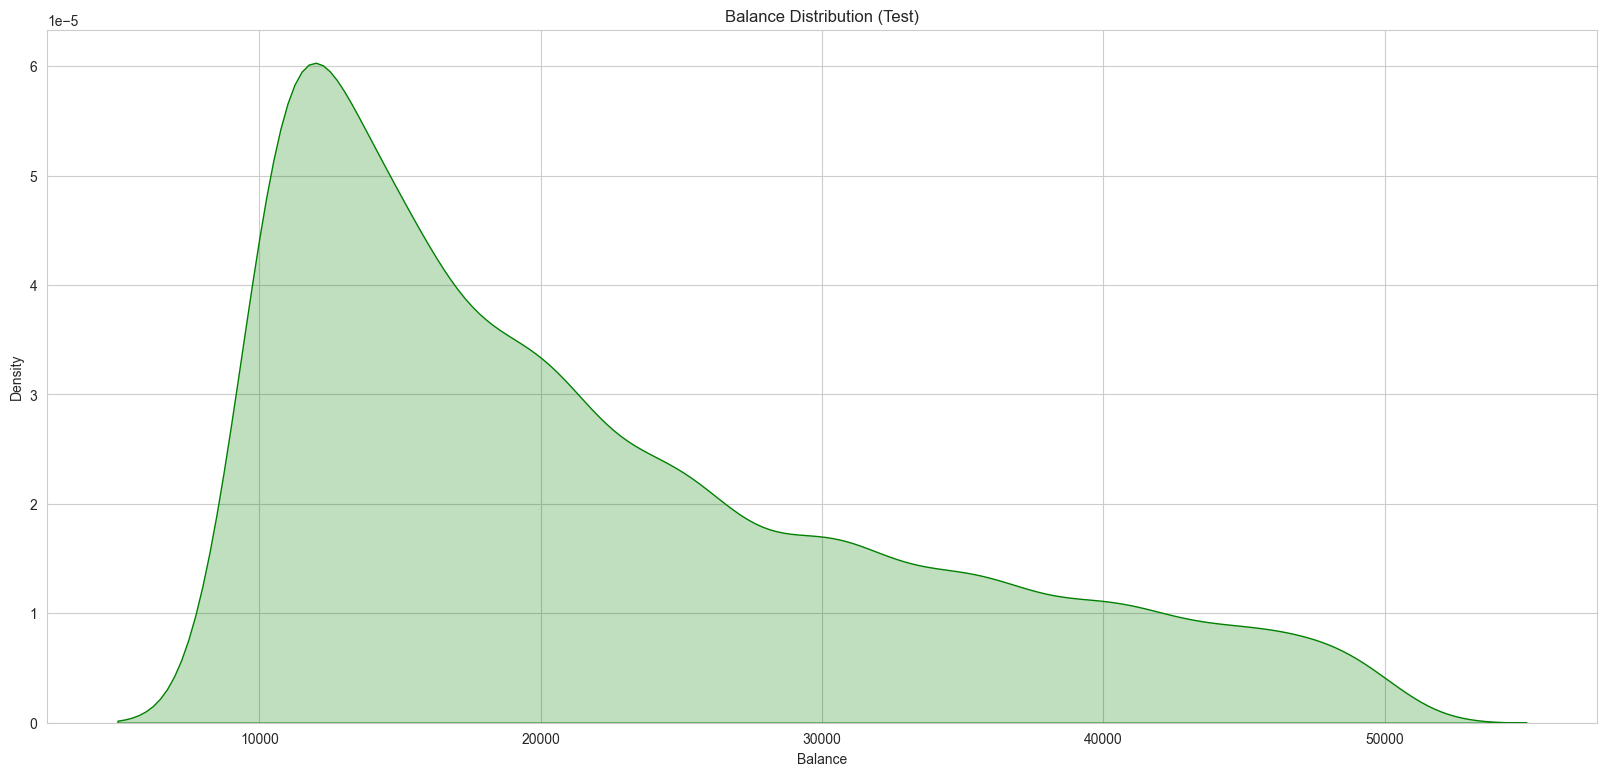

In [57]:
df_graph = df_train[df_train["Product2"] > 0]
plt.show()
fig, ax = plt.subplots(figsize=(20, 9))
sns.kdeplot(x="Balance", data=df_graph, color="green", fill=True, ax=ax)
plt.title("Balance Distribution (Test)")
plt.show()

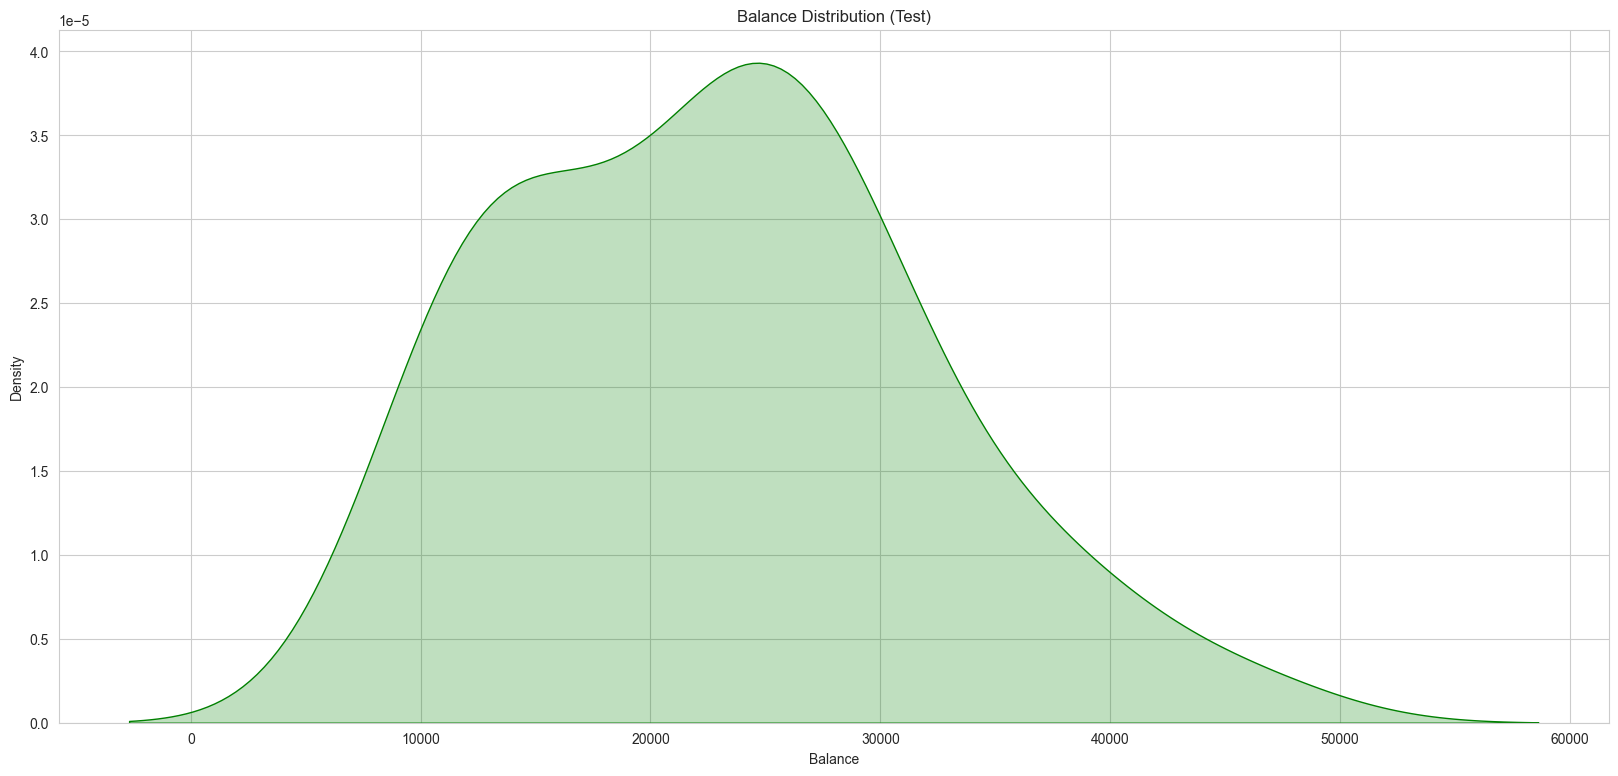

In [58]:
df_graph = df_train_cleaned[df_train_cleaned["Product2"] > 0]
plt.show()
fig, ax = plt.subplots(figsize=(20, 9))
sns.kdeplot(x="Balance", data=df_graph, color="green", fill=True, ax=ax)
plt.title("Balance Distribution (Test)")
plt.show()

In [59]:
df_test.groupby(by=["PreviousCampaignResult"], as_index=False)[
    ["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]
].sum()

,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6
0,0,271,238,2,121,24,57


In [60]:
df_train.groupby(by=["Target", "PreviousCampaignResult"], as_index=False)[
    ["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]
].sum()

,Target,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6
0,0,0,7035,3869,39,2656,564,1175
1,0,1,7,25,0,8,1,1
2,1,0,5781,6342,74,3230,848,1501
3,1,1,5,31,0,4,3,3
4,1,2,0,2,0,0,0,0


In [61]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[
    [
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
    ]
].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[
    [
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
    ]
].sum()

In [62]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,Target
0,0,733629.46,147335.47,1156773.3,21445705.51,9687102.86,13126441.11,146564.05,2248978.04,2120120.77,2


In [63]:
group_train_campaign_result

,Target,PreviousCampaignResult,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9
0,0,0,5777994.85,1872849.91,19822015.24,2.912308e+08,1.246974e+08,2.274376e+08,2259044.21,31851746.70,22950749.67
1,0,1,142165.75,10960.00,151084.27,1.683877e+06,1.367482e+06,1.431573e+06,3834.85,303474.57,122480.22
2,1,0,14079835.86,4381448.94,41915385.93,5.578995e+08,2.466253e+08,3.342478e+08,4206004.19,64886435.04,48593491.02
3,1,1,22246.89,25962.69,286760.71,3.250159e+06,3.046298e+06,1.942281e+06,7292.84,378457.59,245547.99
4,1,2,0.00,300.00,59884.30,1.114593e+05,9.702058e+04,1.786897e+05,0.00,9100.00,2298.57


In [64]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [65]:
group_campaign_result

,PreviousCampaignResult,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,Target
0,0,733629.46,147335.47,1156773.30,2.144571e+07,9.687103e+06,1.312644e+07,146564.05,2248978.04,2120120.77,2
0,0,5777994.85,1872849.91,19822015.24,2.912308e+08,1.246974e+08,2.274376e+08,2259044.21,31851746.70,22950749.67,0
1,1,142165.75,10960.00,151084.27,1.683877e+06,1.367482e+06,1.431573e+06,3834.85,303474.57,122480.22,0
2,0,14079835.86,4381448.94,41915385.93,5.578995e+08,2.466253e+08,3.342478e+08,4206004.19,64886435.04,48593491.02,1
3,1,22246.89,25962.69,286760.71,3.250159e+06,3.046298e+06,1.942281e+06,7292.84,378457.59,245547.99,1
4,2,0.00,300.00,59884.30,1.114593e+05,9.702058e+04,1.786897e+05,0.00,9100.00,2298.57,1


In [66]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

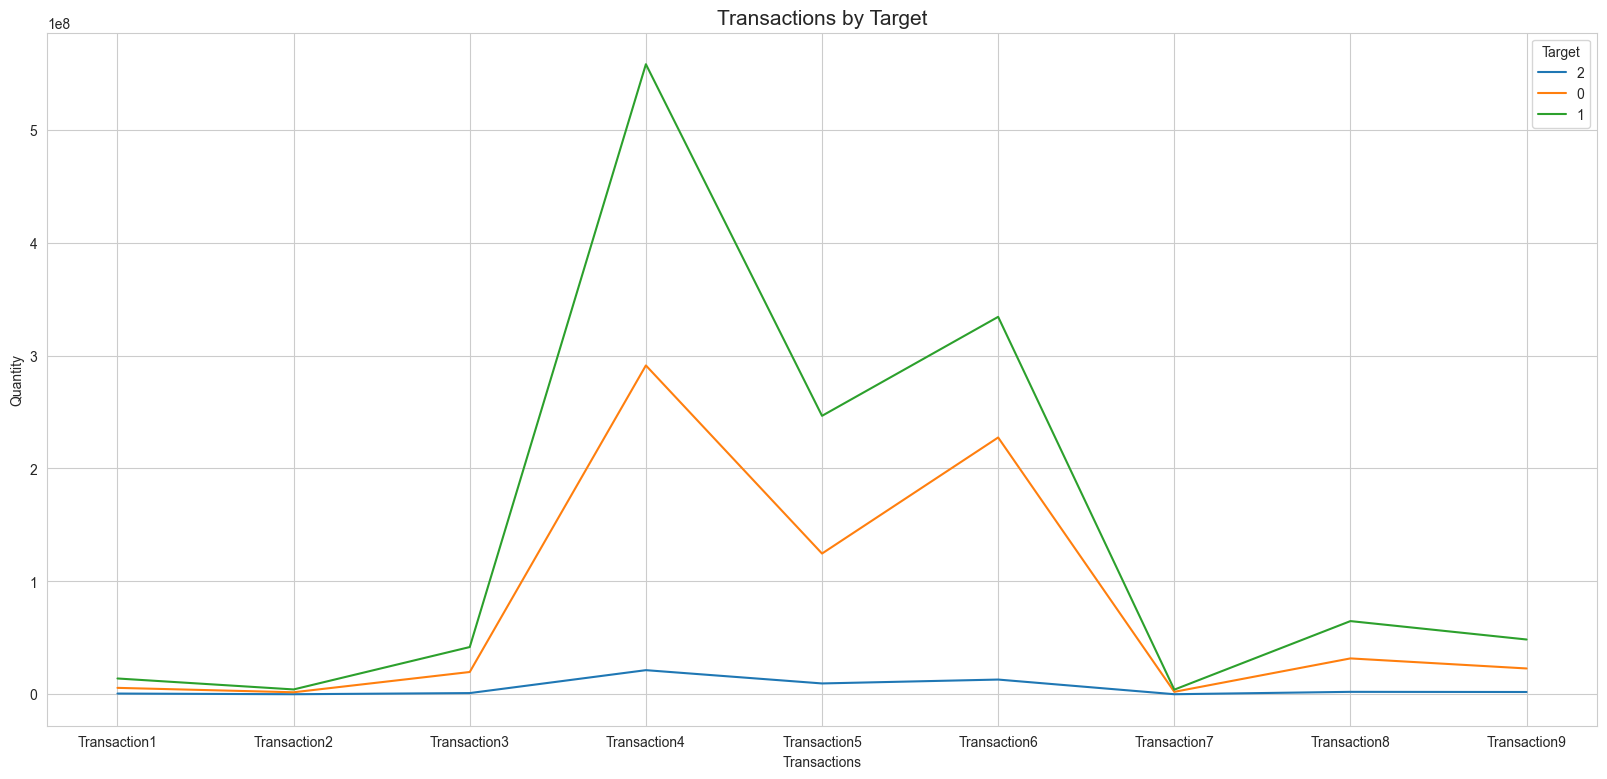

In [67]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("Transactions by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [68]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[["Product1", "Product2", "Product3", "Product4", "Product5", "Product6"]].sum()

In [69]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Target
0,0,271,238,2,121,24,57,2


In [70]:
group_train_campaign_result

,Target,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6
0,0,0,7035,3869,39,2656,564,1175
1,0,1,7,25,0,8,1,1
2,1,0,5781,6342,74,3230,848,1501
3,1,1,5,31,0,4,3,3
4,1,2,0,2,0,0,0,0


In [71]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [72]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

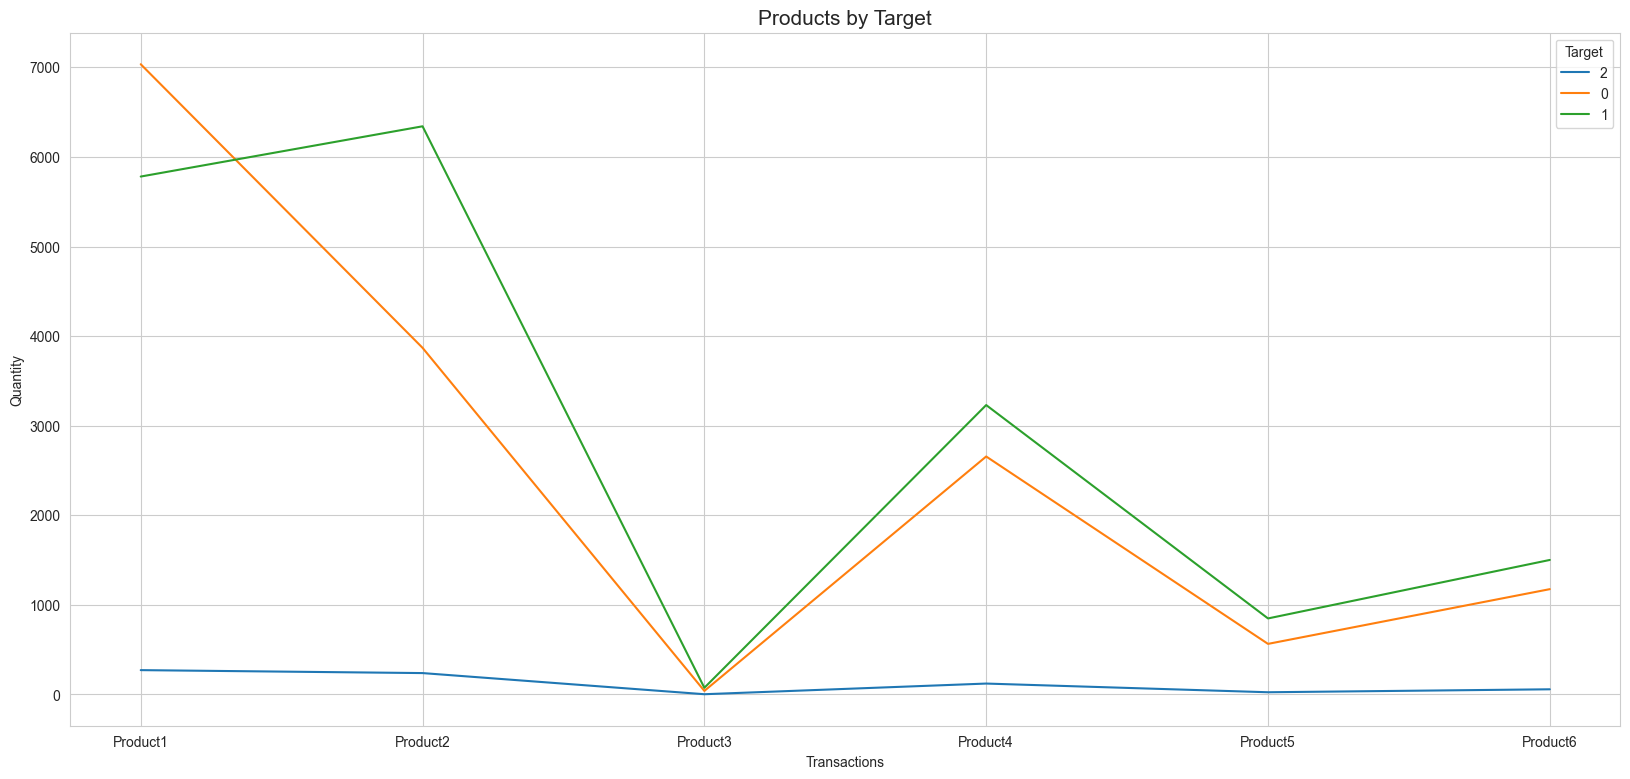

In [73]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("Products by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [74]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[
    [
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
    ]
].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[
    [
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
    ]
].sum()

In [75]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,Target
0,0,316,436,119,193,272,143,31,2


In [76]:
group_train_campaign_result

,Target,PreviousCampaignResult,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7
0,0,0,6310,9427,2677,3859,5783,3222,523
1,0,1,11,16,4,4,21,2,1
2,1,0,6278,9854,2597,4053,6461,3201,711
3,1,1,10,23,4,6,14,2,1
4,1,2,1,2,0,0,0,0,0


In [77]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [78]:
group_campaign_result

,PreviousCampaignResult,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,Target
0,0,316,436,119,193,272,143,31,2
0,0,6310,9427,2677,3859,5783,3222,523,0
1,1,11,16,4,4,21,2,1,0
2,0,6278,9854,2597,4053,6461,3201,711,1
3,1,10,23,4,6,14,2,1,1
4,2,1,2,0,0,0,0,0,1


In [79]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

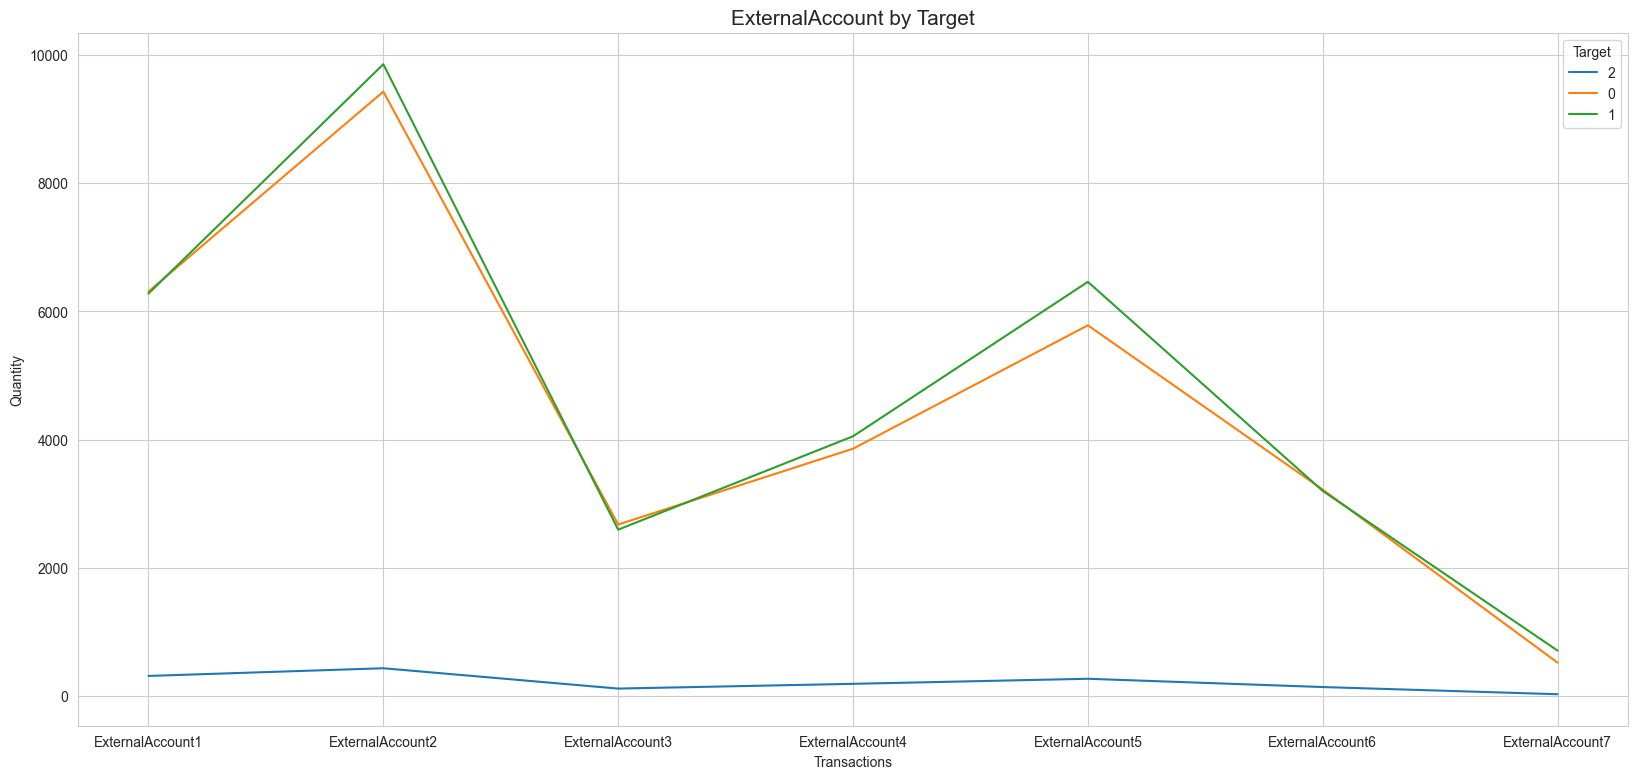

In [80]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("ExternalAccount by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [81]:
group_train_campaign_result = df_train[df_train["PreviousCampaignResult"] == 0][
    ["ActivityIndicator", "Target"]
]

In [82]:
group_test_campaign_result = df_test[df_test["PreviousCampaignResult"] == 0][
    ["ActivityIndicator"]
]
group_test_campaign_result["Target"] = 2

In [83]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [84]:
group_campaign_result

,ActivityIndicator,Target
0,0,2
1,0,2
2,0,2
3,0,2
4,10,2
...,...,...
63994,4,0
63995,0,0
63996,0,1
63997,2,0


In [85]:
group_campaign_result = group_campaign_result.groupby(by=["Target"], as_index=False)[
    ["ActivityIndicator"]
].sum()

In [86]:
group_campaign_result

,Target,ActivityIndicator
0,0,425139
1,1,828905
2,2,29431


In [87]:
group_campaign_result["Percentage"] = 0

In [88]:
group_campaign_result.loc[
    group_campaign_result["Target"].isin([0, 1]), "Percentage"
] = (
    group_campaign_result[group_campaign_result["Target"].isin([0, 1])][
        "ActivityIndicator"
    ]
    / group_campaign_result[group_campaign_result["Target"].isin([0, 1])][
        "ActivityIndicator"
    ].sum()
) * 100

In [89]:
group_campaign_result.loc[group_campaign_result["Target"] == 2, "Percentage"] = (
    group_campaign_result[group_campaign_result["Target"] == 2]["ActivityIndicator"]
    / group_campaign_result[group_campaign_result["Target"] == 2][
        "ActivityIndicator"
    ].sum()
) * 100

In [90]:
group_campaign_result

,Target,ActivityIndicator,Percentage
0,0,425139,33.901442
1,1,828905,66.098558
2,2,29431,100.000000


In [91]:
group_campaign_result.set_index("Target", inplace=True)

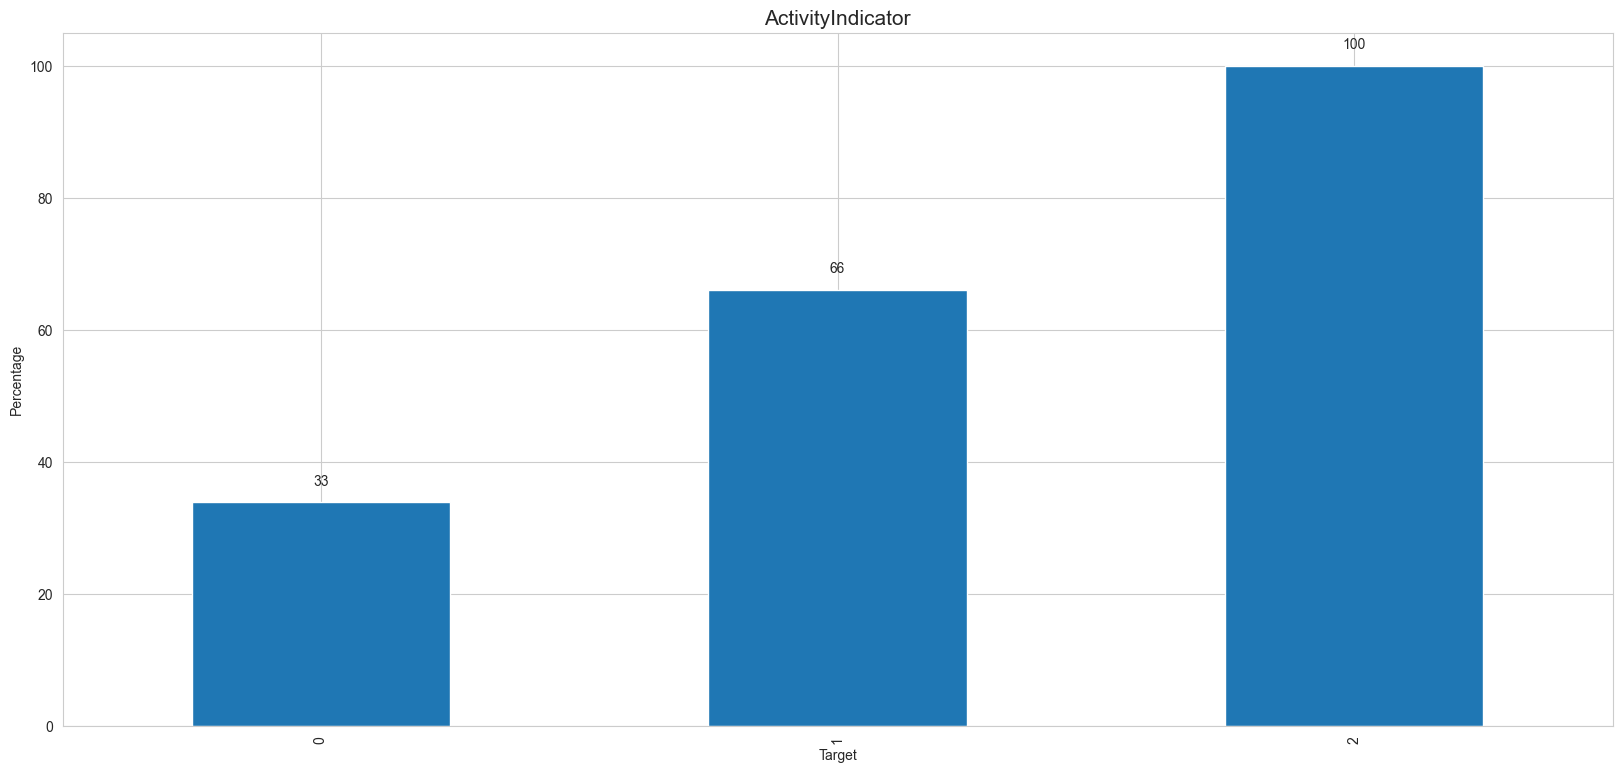

In [92]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
group_campaign_result["Percentage"].plot(kind="bar", ax=ax)
[
    ax.bar_label(
        cont,
        padding=10,
        fmt="%d",
    )
    for cont in ax.containers
]
plt.xlabel("Target")
plt.ylabel("Percentage")
plt.title("ActivityIndicator", fontsize=15).set_position([0.5, 1.05])

plt.show()

In [93]:
group_train_campaign_result = df_train.groupby(
    by=["Target", "RegularInteractionIndicator"], as_index=False
).agg(Total=("RegularInteractionIndicator", "sum"))

In [94]:
group_test_campaign_result = df_test.groupby(
    by=["RegularInteractionIndicator"], as_index=False
).agg(Total=("RegularInteractionIndicator", "sum"))
group_test_campaign_result["Target"] = 2

In [95]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [96]:
group_campaign_result

,RegularInteractionIndicator,Total,Target
0,0,0,2
1,1,385,2
2,2,220,2
3,3,90,2
4,4,68,2
5,5,65,2
6,6,24,2
7,9,9,2
8,15,15,2
0,0,0,0


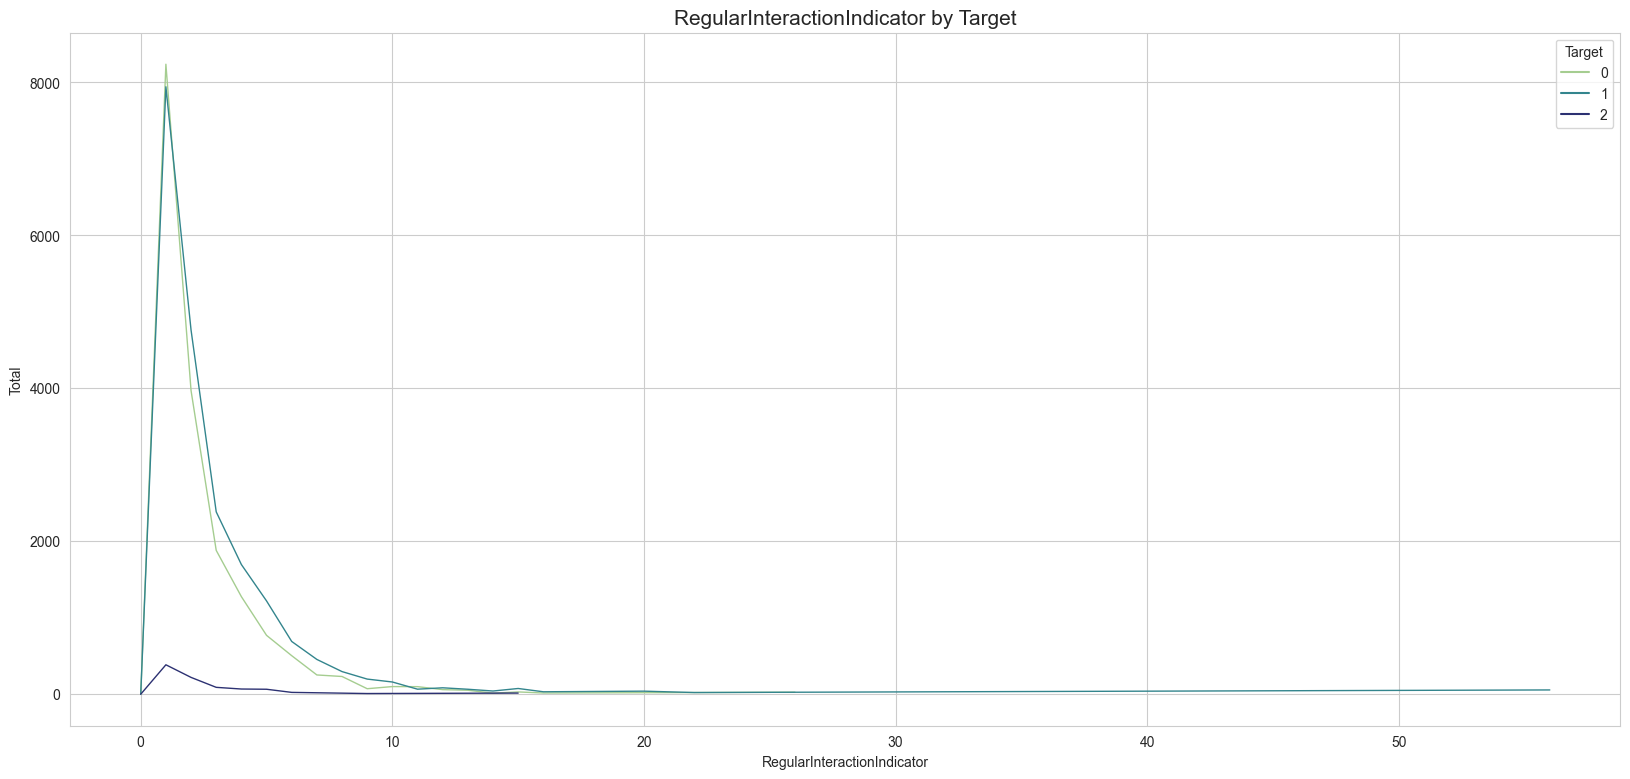

In [97]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
sns.lineplot(
    x=group_campaign_result["RegularInteractionIndicator"],
    y=group_campaign_result["Total"],
    hue=group_campaign_result["Target"],
    palette=sns.color_palette("crest", as_cmap=True),
    estimator=None,
    lw=1,
    markers=True,
    ax=ax,
)
plt.xlabel("RegularInteractionIndicator")
plt.ylabel("Total")
plt.title("RegularInteractionIndicator by Target", fontsize=15)

plt.legend(title="Target")
plt.show()

In [98]:
group_test_campaign_result = df_test.groupby(
    by=["PreviousCampaignResult"], as_index=False
)[
    [
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
    ]
].sum()
group_train_campaign_result = df_train.groupby(
    by=["Target", "PreviousCampaignResult"], as_index=False
)[
    [
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
    ]
].sum()

In [99]:
group_test_campaign_result["Target"] = 2
group_test_campaign_result

,PreviousCampaignResult,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,Target
0,0,2036.5,2715.95,2053.5,2601.0,2805.8,2477.75,2137.6,2


In [100]:
group_train_campaign_result

,Target,PreviousCampaignResult,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7
0,0,0,44073.200,58681.100,44467.350,56247.100,60086.350,53635.900,45139.000
1,0,1,63.250,80.600,63.450,74.200,83.700,76.000,55.250
2,1,0,44097.550,58681.800,44472.600,56058.850,60237.200,53623.400,45123.150
3,1,1,65.225,83.125,65.925,82.925,83.625,79.625,60.475
4,1,2,2.500,3.350,2.550,3.800,3.550,3.150,3.600


In [101]:
group_campaign_result = pd.concat(
    [group_test_campaign_result, group_train_campaign_result]
)
del group_test_campaign_result
del group_train_campaign_result

In [102]:
group_campaign_result

,PreviousCampaignResult,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,Target
0,0,2036.500,2715.950,2053.500,2601.000,2805.800,2477.750,2137.600,2
0,0,44073.200,58681.100,44467.350,56247.100,60086.350,53635.900,45139.000,0
1,1,63.250,80.600,63.450,74.200,83.700,76.000,55.250,0
2,0,44097.550,58681.800,44472.600,56058.850,60237.200,53623.400,45123.150,1
3,1,65.225,83.125,65.925,82.925,83.625,79.625,60.475,1
4,2,2.500,3.350,2.550,3.800,3.550,3.150,3.600,1


In [103]:
df_graph = (
    group_campaign_result[group_campaign_result["PreviousCampaignResult"] == 0]
    .loc[:, ~group_campaign_result.columns.isin(["PreviousCampaignResult"])]
    .set_index("Target")
    .transpose()
)

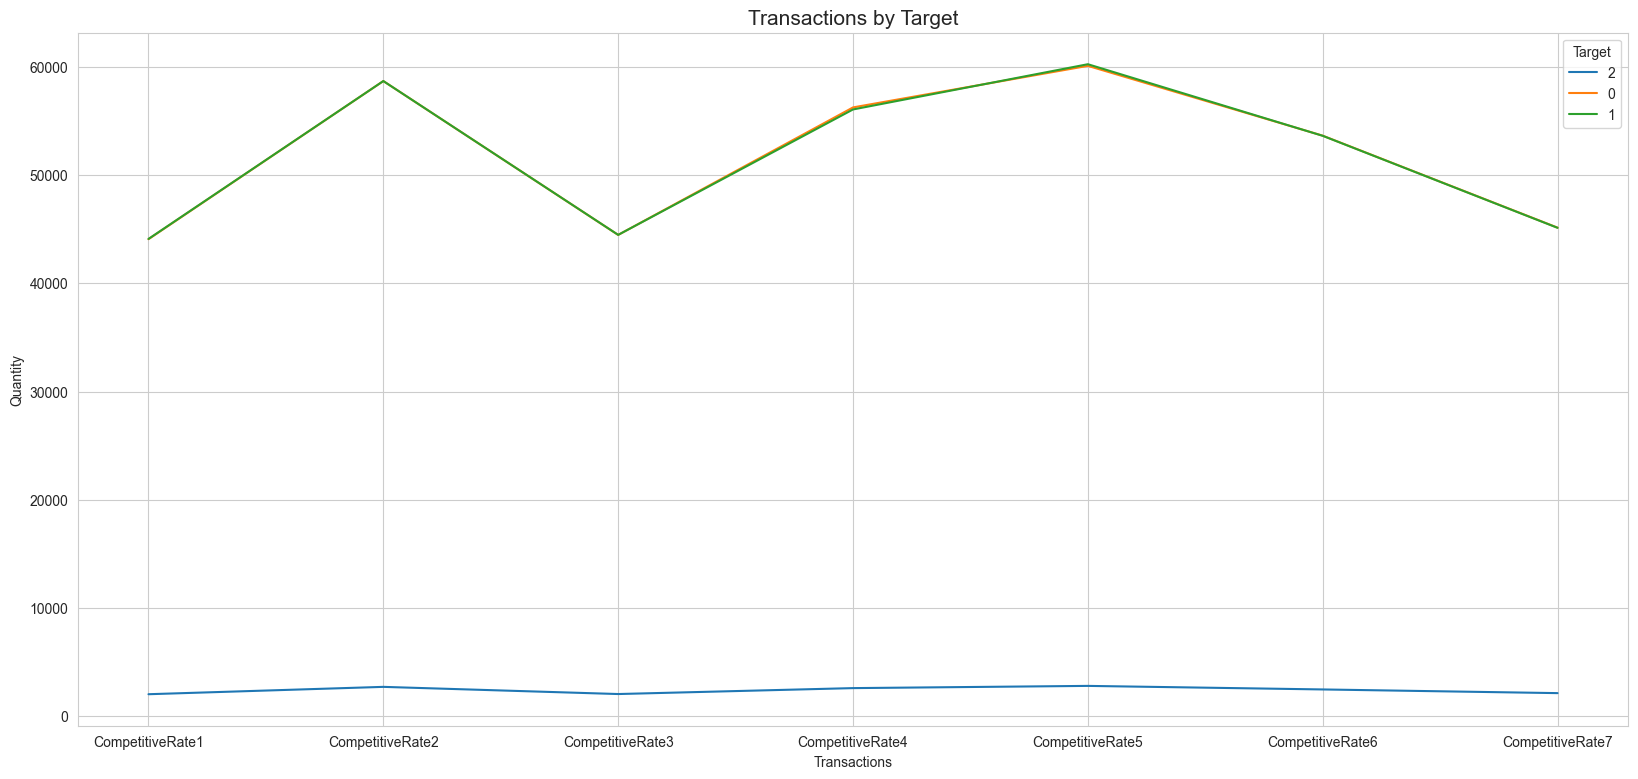

In [104]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Transactions")
plt.ylabel("Quantity")
plt.title("Transactions by Target", fontsize=15).set_position([0.5, 1.05])
df_graph.plot(ax=ax)
plt.show()
del df_graph

In [105]:
# df_graph = df_train[df_train["PreviousCampaignResult"] == 0][["RateBefore", "Product1", "Product2", "Product3", "Product4", "Product5", "Product6", "Target"]].groupby(by=["Target"], as_index=False).sum().set_index('Target').rename(index = {0:'Total'}).T

In [106]:
group_train_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "RateBefore",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "Target",
        ]
    ]
    .groupby(by=["Target"], as_index=False)
    .sum()
)

In [107]:
group_train_campaign_result["%Product1"] = 0
group_train_campaign_result["%Product2"] = 0
group_train_campaign_result["%Product3"] = 0
group_train_campaign_result["%Product4"] = 0
group_train_campaign_result["%Product5"] = 0
group_train_campaign_result["%Product6"] = 0

In [108]:
group_train_campaign_result.loc[:, "Total"] = (
    group_train_campaign_result["Product1"]
    + group_train_campaign_result["Product2"]
    + group_train_campaign_result["Product3"]
    + group_train_campaign_result["Product4"]
    + group_train_campaign_result["Product5"]
    + group_train_campaign_result["Product6"]
)

In [109]:
group_train_campaign_result.loc[:, "%Product1"] = (
    group_train_campaign_result["Product1"] * group_train_campaign_result["RateBefore"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product2"] = (
    group_train_campaign_result["Product2"] * group_train_campaign_result["RateBefore"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product3"] = (
    group_train_campaign_result["Product3"] * group_train_campaign_result["RateBefore"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product4"] = (
    group_train_campaign_result["Product4"] * group_train_campaign_result["RateBefore"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product5"] = (
    group_train_campaign_result["Product5"] * group_train_campaign_result["RateBefore"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product6"] = (
    group_train_campaign_result["Product6"] * group_train_campaign_result["RateBefore"]
) / group_train_campaign_result["Total"]

In [110]:
group_train_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "RateBefore",
        "Total",
    ],
    inplace=True,
)

In [111]:
group_train_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,0,24600.896890,13529.619057,136.380239,9287.843943,1972.268066,4108.891805
1,1,17439.068148,19131.390797,223.229725,9743.675855,2558.091989,4527.943486


In [112]:
group_test_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "RateBefore",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "PreviousCampaignResult",
        ]
    ]
    .groupby(by=["PreviousCampaignResult"], as_index=False)
    .sum()
)

In [113]:
group_test_campaign_result.rename(
    columns={"PreviousCampaignResult": "Target"}, inplace=True
)

In [114]:
group_test_campaign_result["Target"] = 2

In [115]:
group_test_campaign_result["%Product1"] = 0
group_test_campaign_result["%Product2"] = 0
group_test_campaign_result["%Product3"] = 0
group_test_campaign_result["%Product4"] = 0
group_test_campaign_result["%Product5"] = 0
group_test_campaign_result["%Product6"] = 0

In [116]:
group_test_campaign_result.loc[:, "Total"] = (
    group_test_campaign_result["Product1"]
    + group_test_campaign_result["Product2"]
    + group_test_campaign_result["Product3"]
    + group_test_campaign_result["Product4"]
    + group_test_campaign_result["Product5"]
    + group_test_campaign_result["Product6"]
)

In [117]:
group_test_campaign_result.loc[:, "%Product1"] = (
    group_test_campaign_result["Product1"] * group_test_campaign_result["RateBefore"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product2"] = (
    group_test_campaign_result["Product2"] * group_test_campaign_result["RateBefore"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product3"] = (
    group_test_campaign_result["Product3"] * group_test_campaign_result["RateBefore"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product4"] = (
    group_test_campaign_result["Product4"] * group_test_campaign_result["RateBefore"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product5"] = (
    group_test_campaign_result["Product5"] * group_test_campaign_result["RateBefore"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product6"] = (
    group_test_campaign_result["Product6"] * group_test_campaign_result["RateBefore"]
) / group_test_campaign_result["Total"]

In [118]:
group_test_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "RateBefore",
        "Total",
    ],
    inplace=True,
)

In [119]:
group_test_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,2,41512.205979,33074.370728,366.017422,19065.296847,4573.598224,8667.810799


In [120]:
group_campaign_result = pd.concat(
    [group_train_campaign_result, group_test_campaign_result]
)

In [121]:
group_campaign_result_rate_before = group_campaign_result.set_index(
    "Target"
).transpose()

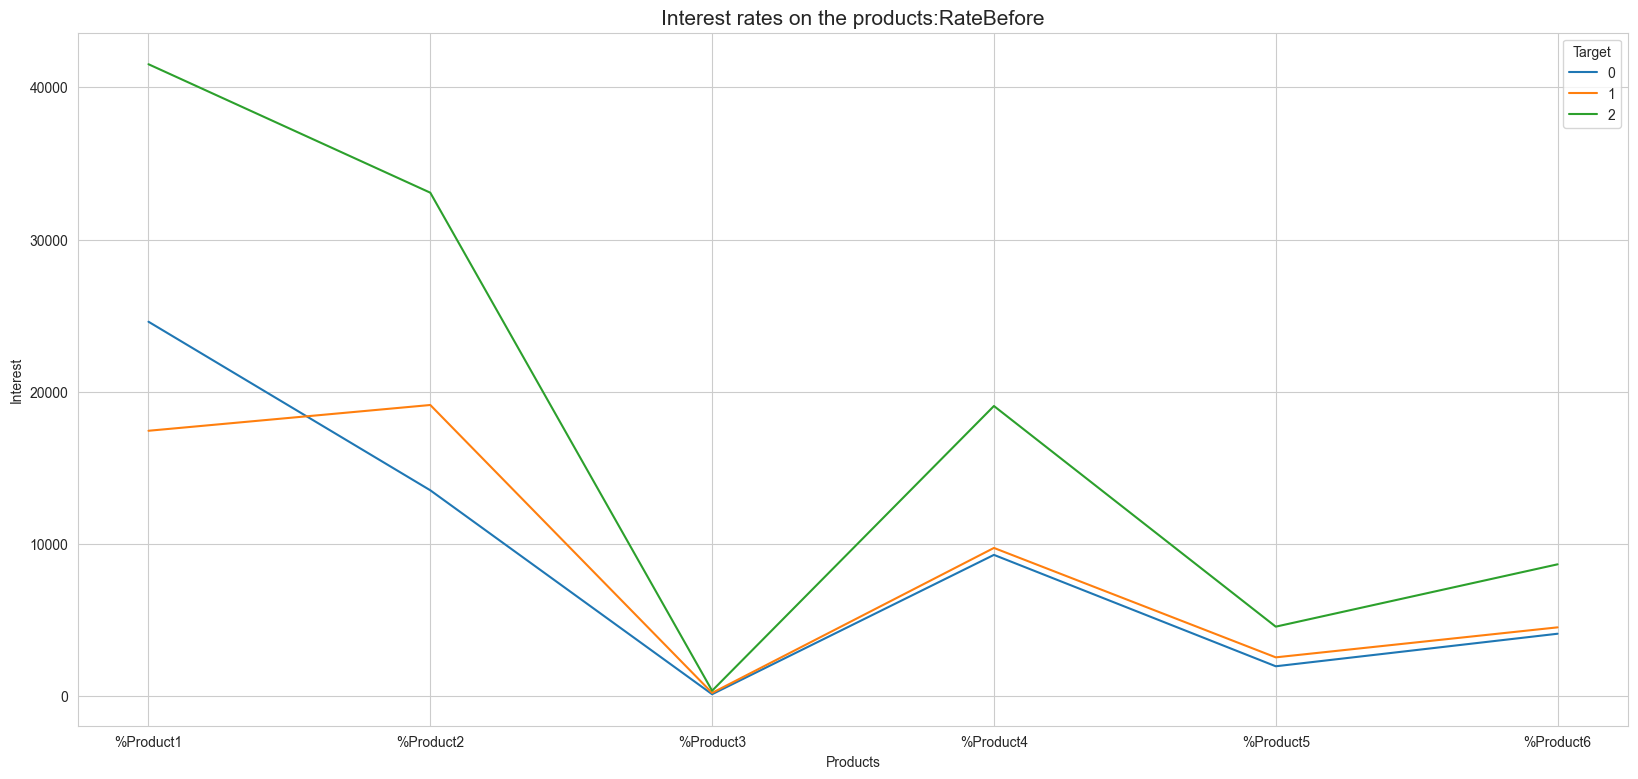

In [122]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Products")
plt.ylabel("Interest")
plt.title("Interest rates on the products:RateBefore", fontsize=15).set_position(
    [0.5, 1.05]
)
group_campaign_result_rate_before.plot(ax=ax)
plt.show()

In [123]:
group_train_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "ReferenceRate",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "Target",
        ]
    ]
    .groupby(by=["Target"], as_index=False)
    .sum()
)

In [124]:
group_train_campaign_result["%Product1"] = 0
group_train_campaign_result["%Product2"] = 0
group_train_campaign_result["%Product3"] = 0
group_train_campaign_result["%Product4"] = 0
group_train_campaign_result["%Product5"] = 0
group_train_campaign_result["%Product6"] = 0

In [125]:
group_train_campaign_result.loc[:, "Total"] = (
    group_train_campaign_result["Product1"]
    + group_train_campaign_result["Product2"]
    + group_train_campaign_result["Product3"]
    + group_train_campaign_result["Product4"]
    + group_train_campaign_result["Product5"]
    + group_train_campaign_result["Product6"]
)

In [126]:
group_train_campaign_result.loc[:, "%Product1"] = (
    group_train_campaign_result["Product1"]
    * group_train_campaign_result["ReferenceRate"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product2"] = (
    group_train_campaign_result["Product2"]
    * group_train_campaign_result["ReferenceRate"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product3"] = (
    group_train_campaign_result["Product3"]
    * group_train_campaign_result["ReferenceRate"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product4"] = (
    group_train_campaign_result["Product4"]
    * group_train_campaign_result["ReferenceRate"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product5"] = (
    group_train_campaign_result["Product5"]
    * group_train_campaign_result["ReferenceRate"]
) / group_train_campaign_result["Total"]
group_train_campaign_result.loc[:, "%Product6"] = (
    group_train_campaign_result["Product6"]
    * group_train_campaign_result["ReferenceRate"]
) / group_train_campaign_result["Total"]

In [127]:
group_train_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "ReferenceRate",
        "Total",
    ],
    inplace=True,
)

In [128]:
group_train_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,0,19275.500962,10600.840543,106.857788,7277.289347,1545.328009,3219.433352
1,1,13667.027439,14993.303583,174.945516,7636.135379,2004.781053,3548.557029


In [129]:
group_test_campaign_result = (
    df_train[df_train["PreviousCampaignResult"] == 0][
        [
            "ReferenceRate",
            "Product1",
            "Product2",
            "Product3",
            "Product4",
            "Product5",
            "Product6",
            "PreviousCampaignResult",
        ]
    ]
    .groupby(by=["PreviousCampaignResult"], as_index=False)
    .sum()
)

In [130]:
group_test_campaign_result.rename(
    columns={"PreviousCampaignResult": "Target"}, inplace=True
)

In [131]:
group_test_campaign_result["Target"] = 2

In [132]:
group_test_campaign_result["%Product1"] = 0
group_test_campaign_result["%Product2"] = 0
group_test_campaign_result["%Product3"] = 0
group_test_campaign_result["%Product4"] = 0
group_test_campaign_result["%Product5"] = 0
group_test_campaign_result["%Product6"] = 0

In [133]:
group_test_campaign_result.loc[:, "Total"] = (
    group_test_campaign_result["Product1"]
    + group_test_campaign_result["Product2"]
    + group_test_campaign_result["Product3"]
    + group_test_campaign_result["Product4"]
    + group_test_campaign_result["Product5"]
    + group_test_campaign_result["Product6"]
)

In [134]:
group_test_campaign_result.loc[:, "%Product1"] = (
    group_test_campaign_result["Product1"] * group_test_campaign_result["ReferenceRate"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product2"] = (
    group_test_campaign_result["Product2"] * group_test_campaign_result["ReferenceRate"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product3"] = (
    group_test_campaign_result["Product3"] * group_test_campaign_result["ReferenceRate"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product4"] = (
    group_test_campaign_result["Product4"] * group_test_campaign_result["ReferenceRate"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product5"] = (
    group_test_campaign_result["Product5"] * group_test_campaign_result["ReferenceRate"]
) / group_test_campaign_result["Total"]
group_test_campaign_result.loc[:, "%Product6"] = (
    group_test_campaign_result["Product6"] * group_test_campaign_result["ReferenceRate"]
) / group_test_campaign_result["Total"]

In [135]:
group_test_campaign_result.drop(
    columns=[
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "ReferenceRate",
        "Total",
    ],
    inplace=True,
)

In [136]:
group_test_campaign_result

,Target,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
0,2,32529.588694,25917.574138,286.816754,14939.853234,3583.940327,6792.226853


In [137]:
group_campaign_result = pd.concat(
    [group_train_campaign_result, group_test_campaign_result]
)

In [138]:
group_campaign_result_reference_rate = group_campaign_result.set_index(
    "Target"
).transpose()

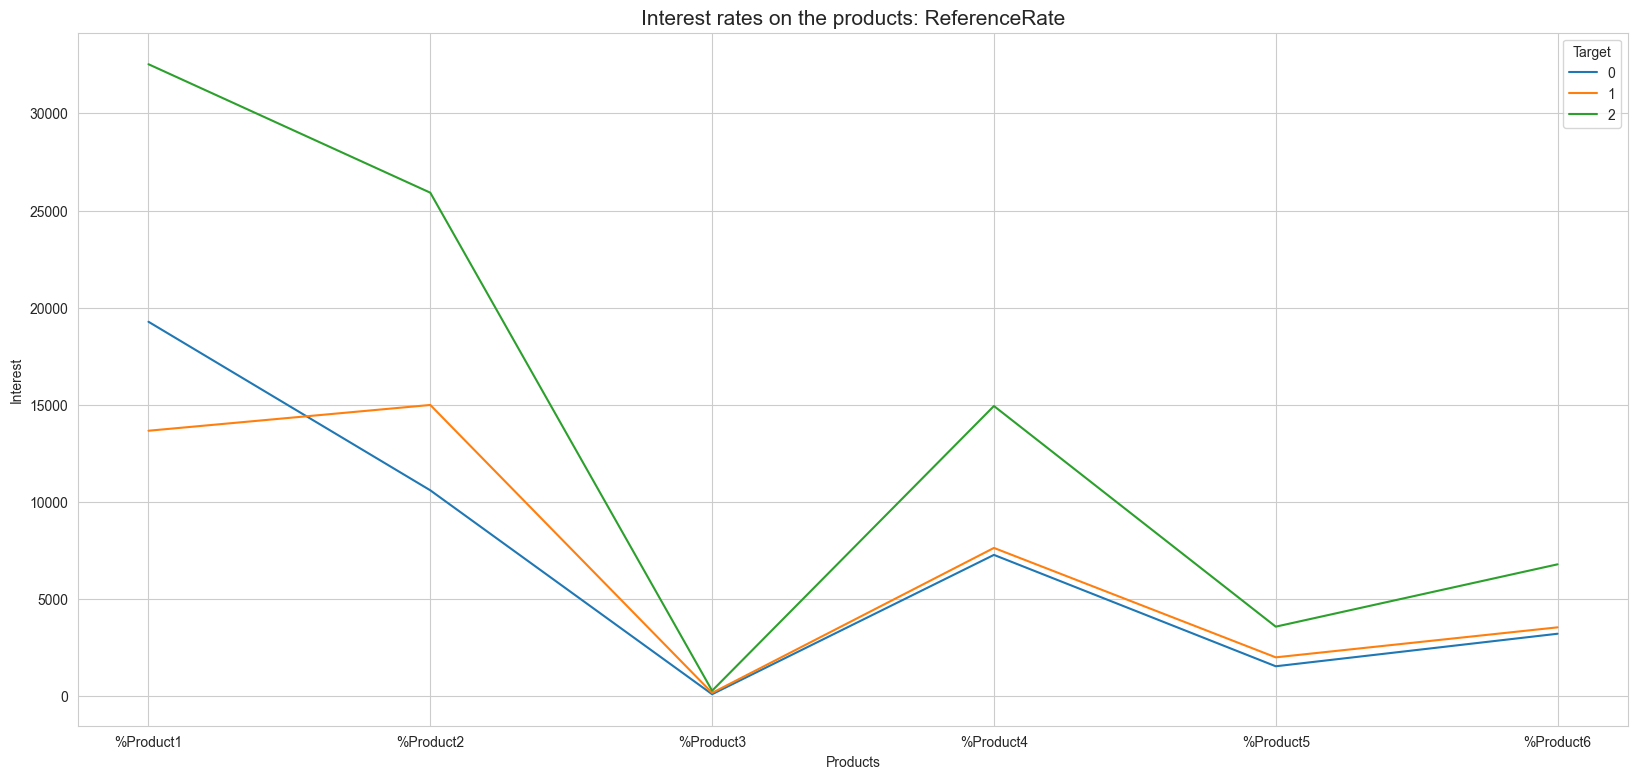

In [139]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Products")
plt.ylabel("Interest")
plt.title("Interest rates on the products: ReferenceRate", fontsize=15).set_position(
    [0.5, 1.05]
)
group_campaign_result_reference_rate.plot(ax=ax)
plt.show()

In [140]:
group_campaign_result_reference_rate = group_campaign_result_reference_rate.T

In [141]:
group_campaign_result_reference_rate

,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
Target,,,,,,
0,19275.500962,10600.840543,106.857788,7277.289347,1545.328009,3219.433352
1,13667.027439,14993.303583,174.945516,7636.135379,2004.781053,3548.557029
2,32529.588694,25917.574138,286.816754,14939.853234,3583.940327,6792.226853


In [142]:
group_campaign_result_reference_rate.loc[
    group_campaign_result_reference_rate.index == 0, "Target"
] = "reference_rate_0"
group_campaign_result_reference_rate.loc[
    group_campaign_result_reference_rate.index == 1, "Target"
] = "reference_rate_1"
group_campaign_result_reference_rate.loc[
    group_campaign_result_reference_rate.index == 2, "Target"
] = "reference_rate_2"

In [143]:
group_campaign_result_reference_rate.set_index("Target", inplace=True)

In [144]:
group_campaign_result_rate_before = group_campaign_result_rate_before.T

In [145]:
group_campaign_result_rate_before

,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
Target,,,,,,
0,24600.896890,13529.619057,136.380239,9287.843943,1972.268066,4108.891805
1,17439.068148,19131.390797,223.229725,9743.675855,2558.091989,4527.943486
2,41512.205979,33074.370728,366.017422,19065.296847,4573.598224,8667.810799


In [146]:
group_campaign_result_rate_before.loc[
    group_campaign_result_rate_before.index == 0, "Target"
] = "rate_before_0"
group_campaign_result_rate_before.loc[
    group_campaign_result_rate_before.index == 1, "Target"
] = "rate_before_1"
group_campaign_result_rate_before.loc[
    group_campaign_result_rate_before.index == 2, "Target"
] = "rate_before_2"

In [147]:
group_campaign_result_rate_before.set_index("Target", inplace=True)

In [148]:
group_campaign_result_total = pd.concat(
    [group_campaign_result_rate_before, group_campaign_result_reference_rate]
)

In [149]:
group_campaign_result_total

,%Product1,%Product2,%Product3,%Product4,%Product5,%Product6
Target,,,,,,
rate_before_0,24600.896890,13529.619057,136.380239,9287.843943,1972.268066,4108.891805
rate_before_1,17439.068148,19131.390797,223.229725,9743.675855,2558.091989,4527.943486
rate_before_2,41512.205979,33074.370728,366.017422,19065.296847,4573.598224,8667.810799
reference_rate_0,19275.500962,10600.840543,106.857788,7277.289347,1545.328009,3219.433352
reference_rate_1,13667.027439,14993.303583,174.945516,7636.135379,2004.781053,3548.557029
reference_rate_2,32529.588694,25917.574138,286.816754,14939.853234,3583.940327,6792.226853


In [150]:
group_campaign_result_total = group_campaign_result_total.T

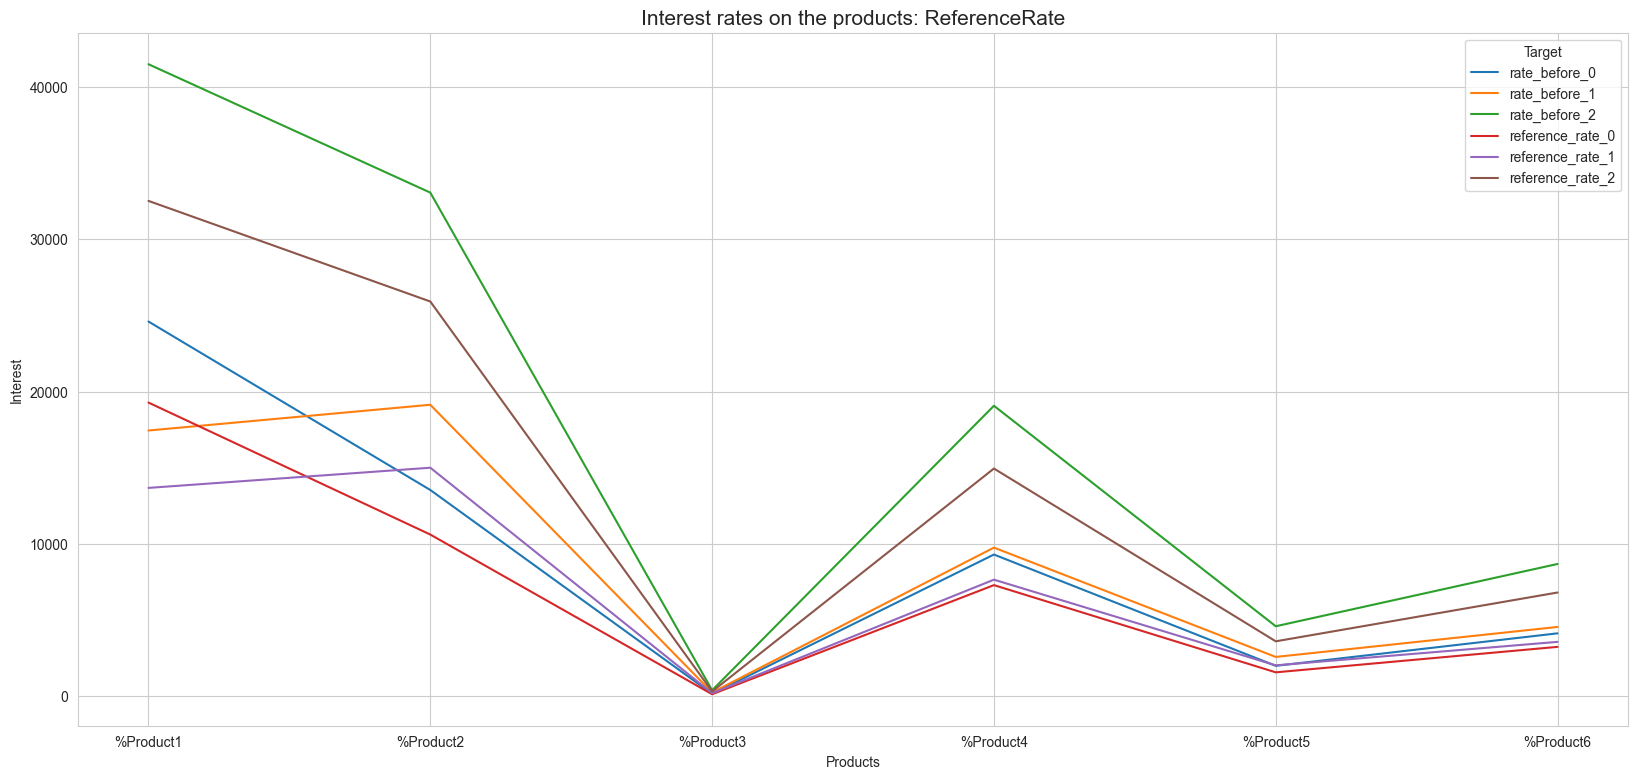

In [151]:
plt.close("all")
fig, ax = plt.subplots(figsize=(20, 9))
plt.xlabel("Products")
plt.ylabel("Interest")
plt.title("Interest rates on the products: ReferenceRate", fontsize=15).set_position(
    [0.5, 1.05]
)
group_campaign_result_total.plot(ax=ax)
plt.show()

In [152]:
del group_campaign_result_total
del group_campaign_result_rate_before
del group_campaign_result_reference_rate

In [153]:
df_train[
    [
        "Balance",
        "Transaction1",
        "Transaction2",
        "Transaction3",
        "Transaction4",
        "Transaction5",
        "Transaction6",
        "Transaction7",
        "Transaction8",
        "Transaction9",
        "Target",
    ]
]

,Balance,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,Target
0,43824.59,0.00,0.00,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0
1,11256.21,0.00,0.00,0.0,8525.0,0.00,0.00,0.0,0.0,0.0,1
2,18795.11,13422.35,800.00,0.0,0.0,0.00,13123.28,0.0,0.0,0.0,1
3,22274.72,0.00,0.00,0.0,1000.0,23900.00,0.00,0.0,0.0,0.0,0
4,47923.40,0.00,0.00,0.0,0.0,2000.00,27629.11,0.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...
63994,40444.92,0.00,747.18,0.0,0.0,11496.44,22242.00,0.0,0.0,0.0,0
63995,47395.91,0.00,0.00,0.0,300.0,0.00,0.00,0.0,0.0,0.0,0
63996,10086.31,0.00,0.00,0.0,0.0,0.00,0.00,0.0,0.0,0.0,1
63997,26452.64,0.00,0.00,0.0,14300.0,0.00,0.00,0.0,0.0,0.0,0


In [154]:
df_train[
    (df_train["Transaction1"] == 0)
    & (df_train["Transaction2"] == 0)
    & (df_train["Transaction3"] == 0)
    & (df_train["Transaction4"] == 0)
    & (df_train["Transaction5"] == 0)
    & (df_train["Transaction6"] == 0)
    & (df_train["Transaction7"] == 0)
    & (df_train["Transaction8"] == 0)
    & (df_train["Transaction9"] == 0)
    & (df_train["Target"] == 1)
    & (df_train["PreviousCampaignResult"] == 0)
][
    [
        "Customer_id",
        "Balance",
        "PreviousCampaignResult",
        "Product1",
        "Product2",
        "Product3",
        "Product4",
        "Product5",
        "Product6",
        "ExternalAccount1",
        "ExternalAccount2",
        "ExternalAccount3",
        "ExternalAccount4",
        "ExternalAccount5",
        "ExternalAccount6",
        "ExternalAccount7",
        "ActivityIndicator",
        "RegularInteractionIndicator",
        "CompetitiveRate1",
        "CompetitiveRate2",
        "CompetitiveRate3",
        "CompetitiveRate4",
        "CompetitiveRate5",
        "CompetitiveRate6",
        "CompetitiveRate7",
        "RateBefore",
        "ReferenceRate",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
Balance,4165.0,22144.467450,10795.166343,10000.000,13063.480,19150.670,29145.560,49999.550
PreviousCampaignResult,4165.0,0.000000,0.000000,0.000,0.000,0.000,0.000,0.000
Product1,4165.0,0.127011,0.333025,0.000,0.000,0.000,0.000,1.000
Product2,4165.0,0.029772,0.169978,0.000,0.000,0.000,0.000,1.000
Product3,4165.0,0.000000,0.000000,0.000,0.000,0.000,0.000,0.000
Product4,4165.0,0.036255,0.186945,0.000,0.000,0.000,0.000,1.000
Product5,4165.0,0.012245,0.109990,0.000,0.000,0.000,0.000,1.000
Product6,4165.0,0.024250,0.153842,0.000,0.000,0.000,0.000,1.000
ExternalAccount1,4165.0,0.194478,0.395846,0.000,0.000,0.000,0.000,1.000
ExternalAccount2,4165.0,0.285954,0.451922,0.000,0.000,0.000,1.000,1.000


In [155]:
df_train[
    df_train.loc[:, ~df_train.columns.isin(["Target", "Customer_id"])].duplicated(
        keep=False
    )
]

,Customer_id,Target,Balance,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,ActivityIndicator,RegularInteractionIndicator,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,RateBefore,ReferenceRate,TotalProducts,CountNegativeTransactions,CountPositiveTransactions,CountTransactions,AverageTransactions,AverageInterestRate,TotalExternalAccount,TotalAverageInterest,TotalAverageInterestBalance
18489,CTSP018490,1,11143.58,0,0,1,0,0,0,0,0.0,0.0,0.0,10000.0,0.0,525.0,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,1,0,2,2,10525.0,1.467857,1,154.491964,153.224225
53008,CTSP053009,1,11143.58,0,0,1,0,0,0,0,0.0,0.0,0.0,10000.0,0.0,525.0,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,1,0,2,2,10525.0,1.467857,1,154.491964,153.224225


In [ ]:
# Attempt 1
# train = df_train.drop(columns=["Customer_id", "Balance", "Product1", "Product2", "Product3", "Product4", "Product5", "Product6", "Transaction1", "Transaction2", "Transaction3", "Transaction4", "Transaction5", "Transaction6", "Transaction7", "Transaction8", "Transaction9", "ExternalAccount1", "ExternalAccount2", "ExternalAccount3", "ExternalAccount4", "ExternalAccount5", "ExternalAccount6", "ExternalAccount7", "CompetitiveRate1", "CompetitiveRate2", "CompetitiveRate3", "CompetitiveRate4", "CompetitiveRate5", "CompetitiveRate6", "CompetitiveRate7", "RateBefore"])

In [ ]:
# Attempt 2
# train = df_train.drop(columns=["Customer_id", "TotalProducts","Transaction1", "Transaction2", "Transaction3", "Transaction4", "Transaction5", "Transaction6", "Transaction7", "Transaction8", "Transaction9", "CompetitiveRate1", "CompetitiveRate2", "CompetitiveRate3", "CompetitiveRate4", "CompetitiveRate5", "CompetitiveRate6", "CompetitiveRate7", "TotalExternalAccount", "TotalAverageInterest", "TotalAverageInterestBalance"])

In [ ]:
# Attempt 3
# train = df_train.drop(columns=["Customer_id"])

In [ ]:
# Attempt 4
# train = df_train.drop(columns=["Customer_id"])
# train = pd.get_dummies(train, columns=['PreviousCampaignResult'])
# test = pd.get_dummies(df_test, columns=['PreviousCampaignResult'])
# test["PreviousCampaignResult_1"] = 0
# test["PreviousCampaignResult_2"] = 0

In [ ]:
# Attempt 5
# train = df_train.drop(columns=["Customer_id"])
# train = pd.get_dummies(train, columns=['PreviousCampaignResult', 'ActivityIndicator', 'RegularInteractionIndicator'])
# test = pd.get_dummies(df_test, columns=['PreviousCampaignResult', 'ActivityIndicator', 'RegularInteractionIndicator'])
# test["PreviousCampaignResult_1"] = 0
# test["PreviousCampaignResult_2"] = 0

In [290]:
# Attempt 6
train = df_train_cleaned.drop(
    columns=[
        "Customer_id",
        "TotalAverageInterestBalance",
        "TotalAverageInterest",
        "RateBefore",
        "AverageTransactions",
        "AverageInterestRate",
    ]
)
train = pd.get_dummies(
    train,
    columns=[
        "ActivityIndicator",
        # "PreviousCampaignResult",
        "RegularInteractionIndicator",
    ],
)
test = pd.get_dummies(
    df_test,
    columns=[
        "ActivityIndicator",
        # "PreviousCampaignResult",
        "RegularInteractionIndicator",
    ],
)

In [291]:
scaler_columns = [
    "Balance",
    "Transaction1",
    "Transaction2",
    "Transaction3",
    "Transaction4",
    "Transaction5",
    "Transaction6",
    "Transaction7",
    "Transaction8",
    "Transaction9",
    "CompetitiveRate1",
    "CompetitiveRate2",
    "CompetitiveRate3",
    "CompetitiveRate4",
    "CompetitiveRate5",
    "CompetitiveRate6",
    "CompetitiveRate7",
    # "RateBefore",
    "ReferenceRate",
    # "AverageTransactions",
    # "AverageInterestRate",
]
scaler = StandardScaler()
train[scaler_columns] = scaler.fit_transform(train[scaler_columns])
scaler_test = StandardScaler()
test[scaler_columns] = scaler_test.fit_transform(test[scaler_columns])

In [292]:
train.drop_duplicates(inplace=True)

In [293]:
X_train_md = train.drop(["Target"], axis=1)  # Features
y_train_md = train["Target"]  # Target variable
X_test_md = test.loc[:, test.columns.isin(X_train_md.columns)]
random_state = 42  # 42
test_size = 0.2

In [294]:
X = X_train_md  # Features
y = y_train_md  # Target variable
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=random_state
)

In [295]:
def get_metrics(model: object, text_model: str, y_test, y_pred, X_train, y_train):
    print(f"---{text_model}---")
    print(f"{text_model} Accuracy: %.3f" % (accuracy_score(y_test, y_pred) * 100))
    print(f"{text_model} Precision: %.3f" % (precision_score(y_test, y_pred) * 100))
    print(f"{text_model} Recall: %.3f" % (recall_score(y_test, y_pred) * 100))
    print(f"{text_model} F1 score: %.3f" % (f1_score(y_test, y_pred) * 100))
    print(f"{text_model} r2_score:  %.3f" % r2_score(y_test, y_pred))

    print("\n--------")
    print("Training Set")
    print(
        f"Accuracy of {text_model} on training set: %.3f"
        % (model.score(X_train, y_train) * 100)
    )
    print("Test Set")
    print(
        f"Accuracy of {text_model} on training set: %.3f"
        % (model.score(X_test, y_test) * 100)
    )

In [296]:
# Logistic Regression
logr = LogisticRegression(random_state=42)

param_grid = {"C": [4, 0.01, 0.1, 1]}
grid_search = GridSearchCV(logr, param_grid, cv=5, n_jobs=-1)
grid_search.fit(X_train, y_train)

logr = LogisticRegression(C=grid_search.best_params_["C"], random_state=42)
logr.fit(X_train, y_train)
logr_y_pred = logr.predict(X_test)
get_metrics(logr, "LogisticRegression", y_test, logr_y_pred, X_train, y_train)

---LogisticRegression---
LogisticRegression Accuracy: 50.000
LogisticRegression Precision: 37.500
LogisticRegression Recall: 60.000
LogisticRegression F1 score: 46.154
LogisticRegression r2_score:  -1.178

--------
Training Set
Accuracy of LogisticRegression on training set: 89.286
Test Set
Accuracy of LogisticRegression on training set: 50.000


In [297]:
# Linear support vector machines
clf = LinearSVC(random_state=42, C=4)
clf.fit(X_train, y_train)
clf_y_pred = clf.predict(X_test)

get_metrics(clf, "LinearSVC", y_test, clf_y_pred, X_train, y_train)

---LinearSVC---
LinearSVC Accuracy: 78.571
LinearSVC Precision: 66.667
LinearSVC Recall: 80.000
LinearSVC F1 score: 72.727
LinearSVC r2_score:  0.067

--------
Training Set
Accuracy of LinearSVC on training set: 96.429
Test Set
Accuracy of LinearSVC on training set: 78.571


In [317]:
columns_train = X_test.columns.values.tolist()
for column in columns_train:
    if column not in X_test_md.columns:
        X_test_md[column] = 0
X_test_md = X_test_md[columns_train]
y_pred = clf.predict(X_test_md)
result = pd.DataFrame(y_pred, columns=["Target"])
df_test_target = pd.concat([result, df_test], axis=1)

In [327]:
df_test_target[df_test_target["Target"]==1]

,Target,Customer_id,Balance,PreviousCampaignResult,Product1,Product2,Product3,Product4,Product5,Product6,Transaction1,Transaction2,Transaction3,Transaction4,Transaction5,Transaction6,Transaction7,Transaction8,Transaction9,ExternalAccount1,ExternalAccount2,ExternalAccount3,ExternalAccount4,ExternalAccount5,ExternalAccount6,ExternalAccount7,ActivityIndicator,RegularInteractionIndicator,CompetitiveRate1,CompetitiveRate2,CompetitiveRate3,CompetitiveRate4,CompetitiveRate5,CompetitiveRate6,CompetitiveRate7,RateBefore,ReferenceRate,TotalProducts,CountNegativeTransactions,CountPositiveTransactions,CountTransactions,AverageTransactions,AverageInterestRate,TotalExternalAccount,TotalAverageInterest,TotalAverageInterestBalance
0,1,CTSP063999,13341.55,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375,0,0,0,0,0.000000,1.710714,1,0.000000,183.446313
1,1,CTSP064000,18649.81,0,1,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,31188.04,0.0,0.0,0.0,0,0,0,1,0,0,0,0,0,1.025,1.925,1.125,2.375,1.175,1.425,1.475,1.425,1.125,1,0,1,1,3465.337778,1.503571,1,52.103829,209.810362
2,1,CTSP064001,28311.30,0,1,0,0,1,0,0,0.0,0.0,0.0,120.0,0.0,0.00,0.0,0.0,0.0,0,1,0,0,0,0,0,0,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,2,0,1,1,13.333333,1.789286,1,0.238571,389.280375
3,1,CTSP064002,18066.61,0,1,0,0,0,0,0,0.0,0.0,0.0,5000.0,0.0,0.00,0.0,0.0,0.0,0,0,0,0,0,1,0,0,0,1.025,1.925,1.125,2.375,1.175,1.425,1.475,1.425,1.125,1,0,1,1,555.555556,1.503571,1,8.353175,203.249362
4,1,CTSP064003,10512.30,0,0,0,0,0,0,0,0.0,0.0,0.0,1300.0,1400.0,0.00,0.0,0.0,0.0,0,1,0,0,0,0,0,10,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,0,0,2,2,300.000000,1.789286,1,5.367857,144.544125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1475,1,CTSP065474,16311.39,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,1.575,1.575,1.575,1.575,1.575,1.875,0.525,1.875,1.375,0,0,0,0,0.000000,1.467857,1,0.000000,224.281612
1476,1,CTSP065475,22990.01,0,0,0,0,0,0,0,0.0,0.0,0.0,15000.0,0.0,0.00,0.0,0.0,0.0,0,0,0,0,0,1,0,1,0,1.475,1.425,1.425,1.425,2.375,1.725,2.125,1.725,1.375,0,0,1,1,1666.666667,1.710714,1,28.511905,316.112638
1477,1,CTSP065476,16792.16,0,1,0,0,0,0,0,0.0,0.0,0.0,5200.0,0.0,6200.00,0.0,0.0,0.0,0,0,0,0,0,0,0,16,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,1,0,2,2,1266.666667,1.789286,0,22.664286,230.892200
1478,1,CTSP065477,12151.15,0,1,0,0,0,0,0,0.0,0.0,0.0,20540.0,0.0,6083.90,0.0,0.0,0.0,0,1,0,1,0,0,0,4,1,1.425,2.375,1.425,1.675,2.375,1.675,1.575,1.675,1.375,1,0,2,2,2958.211111,1.789286,2,52.930849,167.078313


In [250]:
# k-nearest neighbors
knn = KNeighborsClassifier(p=4, leaf_size=1, n_neighbors=5)
knn.fit(X_train, y_train)
knn_y_pred = knn.predict(X_test)

get_metrics(knn, "KNeighborsClassifier", y_test, knn_y_pred, X_train, y_train)

---KNeighborsClassifier---
KNeighborsClassifier Accuracy: 71.429
KNeighborsClassifier Precision: 60.000
KNeighborsClassifier Recall: 60.000
KNeighborsClassifier F1 score: 60.000
KNeighborsClassifier r2_score:  -0.244

--------
Training Set
Accuracy of KNeighborsClassifier on training set: 60.714
Test Set
Accuracy of KNeighborsClassifier on training set: 71.429


In [264]:
# DecisionTreeClassifier
dcst = DecisionTreeClassifier(random_state=0, min_samples_leaf=9)
dcst.fit(X_train, y_train)
dcst_y_pred = dcst.predict(X_test)

get_metrics(dcst, "DecisionTreeClassifier", y_test, dcst_y_pred, X_train, y_train)

---DecisionTreeClassifier---
DecisionTreeClassifier Accuracy: 50.000
DecisionTreeClassifier Precision: 40.000
DecisionTreeClassifier Recall: 80.000
DecisionTreeClassifier F1 score: 53.333
DecisionTreeClassifier r2_score:  -1.178

--------
Training Set
Accuracy of DecisionTreeClassifier on training set: 71.429
Test Set
Accuracy of DecisionTreeClassifier on training set: 50.000


In [270]:
# MLPClassifier
mlp = MLPClassifier(
    solver="lbfgs", alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=42
)
mlp.fit(X_train, y_train)
mlp_y_pred = mlp.predict(X_test)

get_metrics(mlp, "MLPClassifier", y_test, mlp_y_pred, X_train, y_train)

---MLPClassifier---
MLPClassifier Accuracy: 35.714
MLPClassifier Precision: 35.714
MLPClassifier Recall: 100.000
MLPClassifier F1 score: 52.632
MLPClassifier r2_score:  -1.800

--------
Training Set
Accuracy of MLPClassifier on training set: 55.357
Test Set
Accuracy of MLPClassifier on training set: 35.714


In [278]:
# RandomForestClassifier
rfc = RandomForestClassifier(random_state=42, max_depth=2, n_jobs=4)

# define the hyperparameter space to search over
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7, 50],
}
# create a GridSearchCV object
grid_search = GridSearchCV(rfc, param_grid, cv=5, n_jobs=-1)

# fit the GridSearchCV object to the training data
grid_search.fit(X_train, y_train)

rfc = RandomForestClassifier(
    n_estimators=grid_search.best_params_["n_estimators"],
    max_depth=grid_search.best_params_["max_depth"],
    random_state=42,
)
rfc.fit(X_train, y_train)
rfc_y_pred = rfc.predict(X_test)

get_metrics(rfc, "GridSearchCV", y_test, rfc_y_pred, X_train, y_train)

---GridSearchCV---
GridSearchCV Accuracy: 42.857
GridSearchCV Precision: 36.364
GridSearchCV Recall: 80.000
GridSearchCV F1 score: 50.000
GridSearchCV r2_score:  -1.489

--------
Training Set
Accuracy of GridSearchCV on training set: 100.000
Test Set
Accuracy of GridSearchCV on training set: 42.857
